# Comprensión de los datos y EDA — Modelo de riesgo crediticio

Análisis exploratorio de la base de créditos para predecir `Pago_atiempo` (1 = pagó a tiempo, 0 = no).

**Contenido**

1. Exploración inicial: estructura, caracterización de variables y revisión de nulos
2. Unificación de nulos y corrección de datos inconsistentes
3. Eliminación de variables irrelevantes
4. Conversión a los tipos de dato correctos
5. Análisis univariable (numéricas, categóricas, fecha)
6. Análisis bivariable frente a la variable objetivo
7. Análisis multivariable
8. Atributos derivados candidatos
9. Transformaciones sugeridas
10. Reglas de validación de datos (insumo para la etapa de validación)
11. Conclusiones y siguientes pasos

Los datos se cargan con `Cargar_datos.ipynb` (lectura del Excel + tipos básicos). Aquí se parte de ese `df` y se documenta cada decisión de limpieza.

In [1]:
%run ./Cargar_datos.ipynb

Filas: 10,763 | Columnas: 23


In [2]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

# Copia intacta de lo que entrega Cargar_datos: sirve para medir el antes/después de la limpieza
df_original = df.copy()
print(f"Datos cargados: {df_original.shape[0]:,} filas x {df_original.shape[1]} columnas")

Datos cargados: 10,763 filas x 23 columnas


## 1. Exploración inicial de los datos
### 1.1 Estructura general

In [3]:
df_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  category      
 1   fecha_prestamo                 10763 non-null  datetime64[ns]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  category      
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvi

In [4]:
df_original.sample(5, random_state=42).T

,7662,10469,8116,839,1516
tipo_credito,9,4,4,4,4
fecha_prestamo,2025-03-22 09:44:12,2025-01-23 12:29:10,2025-01-02 08:03:25,2025-05-16 09:29:11,2025-03-19 16:33:03
capital_prestado,"2,201,137.20","990,060.00","2,391,360.00","1,929,896.40","1,608,000.00"
plazo_meses,10,12,12,6,12
edad_cliente,35,35,27,57,59
tipo_laboral,Empleado,Empleado,Empleado,Empleado,Independiente
salario_cliente,1900000,4000000,1900000,9000000,1300000
total_otros_prestamos,1300000,1500000,450000,3000000,150000
cuota_pactada,186984,77538,166067,287616,127114
puntaje,95.23,95.23,95.23,95.23,92.00


**Lectura.** Cada fila es un crédito desembolsado entre noviembre de 2024 y abril de 2026. Hay 22 variables explicativas (información del crédito, del cliente, de su comportamiento en la central de riesgo y de sus saldos) y la variable objetivo `Pago_atiempo`. Las columnas con menos de 10 763 valores no nulos ya delatan dónde hay datos faltantes; se detallan en 1.3.

### 1.2 Caracterización de las variables

Se clasifica cada columna según su **naturaleza estadística** (numérica continua/discreta, categórica nominal/ordinal, dicotómica/politómica, fecha). El conteo de valores únicos se calcula sobre los datos para confirmar la clasificación.

In [5]:
CARACTERIZACION = {
    # columna: (naturaleza, nivel de medición / subtipo)
    "tipo_credito":                  ("Categórica", "Nominal politómica (código de producto)"),
    "fecha_prestamo":                ("Fecha", "Temporal (fecha y hora)"),
    "capital_prestado":              ("Numérica", "Continua (razón)"),
    "plazo_meses":                   ("Numérica", "Discreta (razón)"),
    "edad_cliente":                  ("Numérica", "Discreta (razón)"),
    "tipo_laboral":                  ("Categórica", "Nominal dicotómica"),
    "salario_cliente":               ("Numérica", "Continua (razón)"),
    "total_otros_prestamos":         ("Numérica", "Continua (razón)"),
    "cuota_pactada":                 ("Numérica", "Continua (razón)"),
    "puntaje":                       ("Numérica", "Continua (índice interno)"),
    "puntaje_datacredito":           ("Numérica", "Discreta (índice de la central)"),
    "cant_creditosvigentes":         ("Numérica", "Discreta (conteo)"),
    "huella_consulta":               ("Numérica", "Discreta (conteo)"),
    "saldo_mora":                    ("Numérica", "Continua (razón)"),
    "saldo_total":                   ("Numérica", "Continua (razón)"),
    "saldo_principal":               ("Numérica", "Continua (razón)"),
    "saldo_mora_codeudor":           ("Numérica", "Continua (razón)"),
    "creditos_sectorFinanciero":     ("Numérica", "Discreta (conteo)"),
    "creditos_sectorCooperativo":    ("Numérica", "Discreta (conteo)"),
    "creditos_sectorReal":           ("Numérica", "Discreta (conteo)"),
    "promedio_ingresos_datacredito": ("Numérica", "Continua (razón)"),
    "tendencia_ingresos":            ("Categórica", "Ordinal politómica (Decreciente < Estable < Creciente)"),
    "Pago_atiempo":                  ("Objetivo", "Dicotómica (0 = no, 1 = sí)"),
}

caracterizacion = pd.DataFrame(CARACTERIZACION, index=["naturaleza", "subtipo"]).T
caracterizacion["dtype_actual"] = df_original.dtypes.astype(str)
caracterizacion["únicos"] = df_original.nunique()
caracterizacion["nulos"] = df_original.isna().sum()
caracterizacion["ejemplo"] = df_original.iloc[0]
caracterizacion

,naturaleza,subtipo,dtype_actual,únicos,nulos,ejemplo
tipo_credito,Categórica,Nominal politómica (código de producto),category,6,0,7
fecha_prestamo,Fecha,Temporal (fecha y hora),datetime64[ns],10758,0,2024-12-21 11:31:35
capital_prestado,Numérica,Continua (razón),float64,7306,0,"3,692,160.00"
plazo_meses,Numérica,Discreta (razón),int64,18,0,10
edad_cliente,Numérica,Discreta (razón),int64,54,0,42
tipo_laboral,Categórica,Nominal dicotómica,category,2,0,Independiente
salario_cliente,Numérica,Continua (razón),int64,1385,0,8000000
total_otros_prestamos,Numérica,Continua (razón),int64,1538,0,2500000
cuota_pactada,Numérica,Continua (razón),int64,9836,0,341296
puntaje,Numérica,Continua (índice interno),float64,248,0,88.77


**Lectura.**

- **Numéricas (18):** montos y saldos son continuos con rangos enormes; los conteos (`cant_creditosvigentes`, `huella_consulta`, `creditos_sector*`) y `plazo_meses` son discretos y toman pocos valores (`plazo_meses` solo 18 plazos distintos: el plazo es de hecho una variable casi categórica).
- **Categóricas (3):** `tipo_laboral` es dicotómica; `tipo_credito` es nominal politómica (es un *código*, no una cantidad: no tiene sentido promediarlo); `tendencia_ingresos` es la única **ordinal** (Decreciente < Estable < Creciente).
- **Objetivo:** dicotómica. `saldo_mora_codeudor` tiene solo 4 valores únicos, una pista temprana de que casi no varía.
- `tendencia_ingresos` aparece con `object` y muchos valores únicos: debería tener solo 3 categorías, así que hay valores que no pertenecen al catálogo (se corrige en la sección 2).

### 1.3 Revisión de nulos y duplicados

In [6]:
resumen_nulos = (
    df_original.isna().sum().to_frame("nulos")
    .assign(pct=lambda t: 100 * t["nulos"] / len(df_original))
    .query("nulos > 0")
    .sort_values("pct", ascending=False)
)
print(f"Filas duplicadas: {df_original.duplicated().sum():,}")
resumen_nulos

Filas duplicadas: 0


,nulos,pct
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


In [7]:
fig, ax = plt.subplots(figsize=(8, 0.5 * len(resumen_nulos) + 1))
sns.barplot(x=resumen_nulos["pct"], y=resumen_nulos.index, ax=ax, color="tab:red")
ax.set(title="Porcentaje de valores nulos por columna (datos originales)", xlabel="% nulos", ylabel="")
for i, v in enumerate(resumen_nulos["pct"]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

<Figure size 800x450 with 1 Axes>

**Lectura.**

- No hay filas duplicadas.
- Los nulos se concentran en **`promedio_ingresos_datacredito` (27.2 %) y `tendencia_ingresos` (27.2 %)**. Son casi el mismo grupo de clientes: probablemente personas sin historial de ingresos en la central de riesgo. Es un patrón de **nulo informativo** (no aleatorio), por lo que conviene conservar un indicador de "sin dato".
- `saldo_mora_codeudor` (5.5 %), `saldo_principal` (3.8 %), `saldo_mora` y `saldo_total` (1.4 %) y `puntaje_datacredito` (6 filas) tienen pocos nulos.
- **Ojo:** `isna()` solo detecta los nulos "oficiales". Hay otras formas de representar "no hay dato" (números sentinela como `0`, `-7` o `122` años; números dentro de una columna de texto) que se tratan a continuación.

## 2. Unificación de nulos y corrección de datos inconsistentes

Se busca que **todo "dato ausente" o "dato imposible" quede representado de una sola forma: `NaN`** (`np.nan`), tanto en columnas numéricas como categóricas. Se actúa en tres frentes:

1. **Texto:** quitar espacios y convertir marcadores de texto ("N/A", "null", "", "-"…) en `NaN`.
2. **Catálogos:** valores fuera del catálogo permitido (p. ej. números en `tendencia_ingresos`) → `NaN`.
3. **Rangos:** valores numéricos imposibles o centinela (edad 122, salario 0, puntaje de la central ≤ 0…) → `NaN`.

Los rangos son **hipótesis de negocio razonables** (a confirmar con el área de riesgo) y quedan en una sola estructura (`RANGO_DURO`) que se reutiliza luego como regla de validación.

### 2.1 Diagnóstico: valores que no son nulos, pero tampoco son válidos

In [8]:
CAT_TENDENCIA = ["Decreciente", "Estable", "Creciente"]          # orden lógico (ordinal)
CAT_LABORAL = ["Empleado", "Independiente"]
TOKENS_NULOS = {"", "na", "n/a", "nan", "null", "none", "nulo", "-", "?", "sin dato", "s/d"}

# Rango "duro": fuera de él el valor se considera imposible y se pasa a NaN. (None = sin límite)
RANGO_DURO = {
    "capital_prestado":              (1, None),
    "plazo_meses":                   (1, 60),
    "edad_cliente":                  (18, 100),
    "salario_cliente":               (100_000, 100_000_000),
    "total_otros_prestamos":         (0, None),
    "cuota_pactada":                 (1, None),
    "puntaje_datacredito":           (1, 999),   # 0 y negativos = "sin puntaje", no un puntaje real
    "cant_creditosvigentes":         (0, None),
    "huella_consulta":               (0, None),
    "saldo_mora":                    (0, None),
    "saldo_total":                   (0, None),
    "saldo_principal":               (0, None),
    "saldo_mora_codeudor":           (0, None),
    "creditos_sectorFinanciero":     (0, None),
    "creditos_sectorCooperativo":    (0, None),
    "creditos_sectorReal":           (0, None),
    "promedio_ingresos_datacredito": (1, None),
}


def fuera_de_rango(serie: pd.Series, lo, hi) -> pd.Series:
    """Máscara de valores no nulos que violan el rango [lo, hi]."""
    m = pd.Series(False, index=serie.index)
    if lo is not None:
        m |= serie < lo
    if hi is not None:
        m |= serie > hi
    return m & serie.notna()


filas = []
for col, (lo, hi) in RANGO_DURO.items():
    n = int(fuera_de_rango(df_original[col], lo, hi).sum())
    if n:
        filas.append({"columna": col, "regla": f"fuera de [{lo}, {hi}]", "filas": n})

tend = df_original["tendencia_ingresos"].astype(object)
fuera_cat = tend.notna() & ~tend.isin(CAT_TENDENCIA)
filas.append({"columna": "tendencia_ingresos", "regla": "fuera del catálogo (Creciente/Estable/Decreciente)", "filas": int(fuera_cat.sum())})

diagnostico = pd.DataFrame(filas).assign(pct=lambda t: (100 * t["filas"] / len(df_original)).round(2))
display(diagnostico)

print("Ejemplos de valores fuera del catálogo en tendencia_ingresos:", tend[fuera_cat].head(8).tolist())
print("Edades más frecuentes por encima de 90:", df_original.loc[df_original["edad_cliente"] > 90, "edad_cliente"].value_counts().to_dict())
print("Salarios máximos:", df_original["salario_cliente"].nlargest(5).tolist())

,columna,regla,filas,pct
0,plazo_meses,"fuera de [1, 60]",1,0.01
1,edad_cliente,"fuera de [18, 100]",150,1.39
2,salario_cliente,"fuera de [100000, 100000000]",105,0.98
3,puntaje_datacredito,"fuera de [1, 999]",146,1.36
4,promedio_ingresos_datacredito,"fuera de [1, None]",7,0.07
5,tendencia_ingresos,fuera del catálogo (Creciente/Estable/Decrecie...,58,0.54


Ejemplos de valores fuera del catálogo en tendencia_ingresos: [8315, 0, 158042, 3978, 9147, 8315, 168750, -28589]
Edades más frecuentes por encima de 90: {122: 144, 121: 4, 123: 2}
Salarios máximos: [22000000000, 16991100000, 13258352050, 12450806583, 8252584000]


**Lectura.**

- **`tendencia_ingresos`:** 58 filas traen **números** (0, 8315, 1000000, -28589…) en una columna que debería ser texto con tres categorías. Parecen montos mal ubicados por un error de captura/cargue; no se pueden interpretar como "Creciente/Estable/Decreciente", así que se anulan.
- **`edad_cliente`:** 144 clientes tienen exactamente **122 años** (y unos pocos 121/123). Es un valor *centinela* — la edad real es desconocida — no una edad verdadera. Se anula.
- **`salario_cliente`:** 105 filas fuera de rango: 74 con salarios **mayores a 100 millones (hasta 22 mil millones)**, inverosímiles para un crédito de consumo de ~2.4 M, y 31 con salario 0 (24 casos) o menor a 100 000, que no representan un ingreso real. La regla (100 000 – 100 M) elimina los extremos claramente erróneos sin tocar los salarios altos legítimos (el máximo conservado es ≈ 96 M).
- **`puntaje_datacredito`:** 146 filas con 0 o negativo (p. ej. −7). Un puntaje de central de riesgo va de 1 a 999; 0 significa "sin puntaje".
- **`plazo_meses`:** el plazo de 90 meses es único y contrasta con el resto (máximo habitual 36).
- **`total_otros_prestamos`** también tiene valores de miles de millones, pero no hay un límite de negocio claro, así que no se anula: se trata como outlier en la sección de transformaciones.

### 2.2 Aplicación de la limpieza

La limpieza se encapsula en una función para poder **reutilizarla tal cual** en el pipeline de producción.

In [9]:
def limpiar(datos: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Unifica nulos (NaN) y anula valores imposibles. Devuelve (datos limpios, bitácora de cambios)."""
    d = datos.copy()
    bitacora = []

    # 1) Texto: strip + marcadores de nulo -> NaN; catálogos -> NaN
    for col, catalogo in {"tipo_laboral": CAT_LABORAL, "tendencia_ingresos": CAT_TENDENCIA}.items():
        s = d[col].astype(object)
        s = s.map(lambda v: v.strip() if isinstance(v, str) else v)
        s = s.map(lambda v: np.nan if isinstance(v, str) and v.lower() in TOKENS_NULOS else v)
        fuera = s.notna() & ~s.isin(catalogo)
        if fuera.any():
            bitacora.append({"columna": col, "motivo": "fuera de catálogo", "filas": int(fuera.sum())})
        d[col] = pd.Categorical(s.where(~fuera, np.nan), categories=catalogo, ordered=(col == "tendencia_ingresos"))

    # 2) Numéricas: valores imposibles / centinela -> NaN (se pasa a float para admitir NaN)
    for col, (lo, hi) in RANGO_DURO.items():
        d[col] = d[col].astype("float64")
        fuera = fuera_de_rango(d[col], lo, hi)
        if fuera.any():
            bitacora.append({"columna": col, "motivo": f"fuera de rango [{lo}, {hi}]", "filas": int(fuera.sum())})
        d.loc[fuera, col] = np.nan

    return d, pd.DataFrame(bitacora)


df_limpio, bitacora = limpiar(df_original)
bitacora

,columna,motivo,filas
0,tendencia_ingresos,fuera de catálogo,58
1,plazo_meses,"fuera de rango [1, 60]",1
2,edad_cliente,"fuera de rango [18, 100]",150
3,salario_cliente,"fuera de rango [100000, 100000000]",105
4,puntaje_datacredito,"fuera de rango [1, 999]",146
5,promedio_ingresos_datacredito,"fuera de rango [1, None]",7


In [10]:
comparativo = pd.DataFrame({
    "nulos_antes": df_original.isna().sum(),
    "nulos_después": df_limpio.isna().sum(),
}).assign(nuevos_nulos=lambda t: t["nulos_después"] - t["nulos_antes"]).query("nulos_antes > 0 or nulos_después > 0")
comparativo.sort_values("nulos_después", ascending=False)

,nulos_antes,nulos_después,nuevos_nulos
tendencia_ingresos,2932,2990,58
promedio_ingresos_datacredito,2930,2937,7
saldo_mora_codeudor,590,590,0
saldo_principal,405,405,0
saldo_mora,156,156,0
saldo_total,156,156,0
puntaje_datacredito,6,152,146
edad_cliente,0,150,150
salario_cliente,0,105,105
plazo_meses,0,1,1


**Lectura.** A partir de aquí, **cualquier ausencia es `NaN`**: los números dentro de `tendencia_ingresos`, la edad 122, los salarios inverosímiles y los puntajes de la central ≤ 0 ahora cuentan como nulos reales. Hay más nulos que antes en `salario_cliente`, `edad_cliente`, `puntaje_datacredito` y `tendencia_ingresos`, y eso es deliberado: es preferible reconocer que no se sabe el dato a dejar que un 122 o un 22 000 000 000 distorsionen medias, correlaciones y el modelo. La imputación se decide en la etapa de preparación.

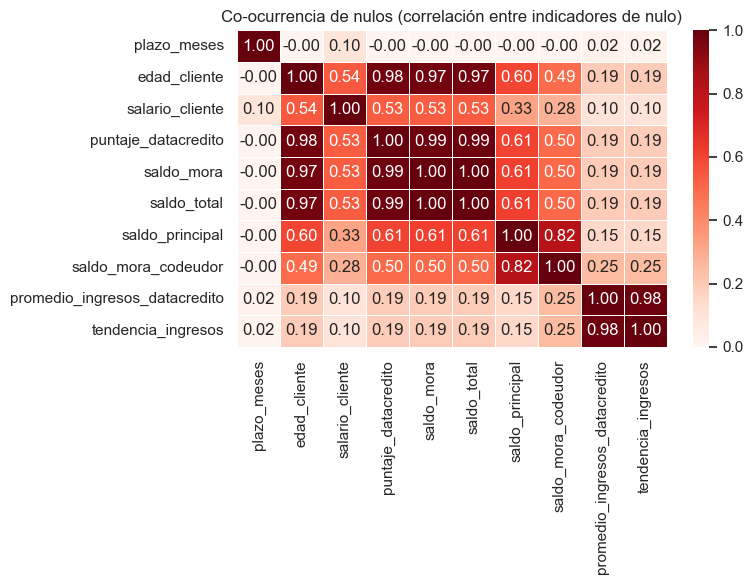

In [11]:
# ¿Los nulos ocurren juntos? Correlación entre indicadores de nulo (1 = siempre faltan a la vez)
cols_con_nulos = df_limpio.columns[df_limpio.isna().any()]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df_limpio[cols_con_nulos].isna().astype(int).corr(), annot=True, fmt=".2f", cmap="Reds",
            vmin=0, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Co-ocurrencia de nulos (correlación entre indicadores de nulo)")
plt.tight_layout()
plt.show()

**Lectura.** `promedio_ingresos_datacredito` y `tendencia_ingresos` faltan **juntos** (correlación ≈ 1): corresponden a clientes sin historial de ingresos en la central. Los demás nulos (saldos) están más aislados. Esto confirma que el nulo de ingresos es un grupo con significado propio y justifica crear un indicador `sin_ingresos_datacredito` (sección 8).

## 3. Eliminación de variables irrelevantes

Una variable es candidata a eliminarse si **(a) es constante o casi constante** (no distingue a unos créditos de otros), **(b) es un identificador** (no generaliza) o **(c) es redundante** con otra (aporta lo mismo). Se miden estos criterios antes de decidir.

In [12]:
cols_explicativas = [c for c in df_limpio.columns if c != TARGET]

relevancia = pd.DataFrame({
    "únicos": df_limpio[cols_explicativas].nunique(),
    "% valor dominante (sobre no nulos)": [
        100 * df_limpio[c].value_counts(normalize=True).iloc[0] for c in cols_explicativas
    ],
    "% nulos": 100 * df_limpio[cols_explicativas].isna().mean(),
})
# Relación con el objetivo (Spearman) para las numéricas
relevancia["spearman_vs_objetivo"] = df_limpio[cols_explicativas].select_dtypes("number").apply(
    lambda s: s.corr(df_limpio[TARGET], method="spearman"))
relevancia.sort_values("% valor dominante (sobre no nulos)", ascending=False).head(8).round(3)

,únicos,% valor dominante (sobre no nulos),% nulos,spearman_vs_objetivo
saldo_mora_codeudor,4,99.97,5.48,0.00
saldo_mora,55,99.48,1.45,-0.11
puntaje,248,87.40,0.00,0.64
creditos_sectorCooperativo,11,82.39,0.00,0.02
tipo_credito,6,71.98,0.00,NaN
tendencia_ingresos,3,68.11,27.78,NaN
tipo_laboral,2,62.75,0.00,NaN
creditos_sectorReal,24,41.12,0.00,-0.02


In [13]:
# Redundancia: saldo_principal vs saldo_total
ambos = df_limpio[["saldo_principal", "saldo_total"]].dropna()
print(f"Spearman saldo_principal vs saldo_total: {ambos.corr(method='spearman').iloc[0, 1]:.3f}")
print(f"Filas donde son exactamente iguales: {(ambos['saldo_principal'] == ambos['saldo_total']).mean():.1%}")
print("Valores distintos de saldo_mora_codeudor:", df_limpio['saldo_mora_codeudor'].value_counts().to_dict())
print(f"IDs o columnas constantes: {[c for c in cols_explicativas if df_limpio[c].nunique() <= 1]}")

Spearman saldo_principal vs saldo_total: 0.946
Filas donde son exactamente iguales: 83.6%
Valores distintos de saldo_mora_codeudor: {0.0: 10170, 2145.0: 1, 30.0: 1, 470.0: 1}
IDs o columnas constantes: []


**Decisiones.**

| Variable | Decisión | Justificación |
|---|---|---|
| `saldo_mora_codeudor` | **Eliminar** | Tiene solo 4 valores distintos y **99.97 % de los datos no nulos es 0** (únicamente 3 filas distintas de cero). No aporta información y su correlación con el objetivo es ≈ 0. |
| `saldo_principal` | **Eliminar** (redundante) | Spearman 0.95 con `saldo_total`; en ≈ 84 % de las filas son **idénticos**. Se conserva `saldo_total` (menos nulos: 156 vs 405). |
| `saldo_mora` | **Conservar** | Aunque 98 % de las filas vale 0, las 55 con mora tienen una tasa de pago de ~64 % frente a ~95 %: poca frecuencia pero **muy informativa**. |
| `fecha_prestamo` | **Conservar** (no como predictor directo) | Sirve para atributos derivados y para hacer la partición temporal train/test. |
| `puntaje` | **Conservar, con alerta** | Ver sección 6: su relación con el objetivo es casi determinista y puede ser *fuga de información*. No se elimina en el EDA; se marca para decisión de negocio. |

No existe una columna identificadora (ID de cliente o crédito) ni columnas constantes.

In [14]:
COLUMNAS_ELIMINAR = ["saldo_mora_codeudor", "saldo_principal"]
df = df_limpio.drop(columns=COLUMNAS_ELIMINAR)
print(f"Columnas eliminadas: {COLUMNAS_ELIMINAR}  ->  quedan {df.shape[1]} columnas")

Columnas eliminadas: ['saldo_mora_codeudor', 'saldo_principal']  ->  quedan 21 columnas


## 4. Conversión a los tipos de dato correctos

Reglas aplicadas:

- **Categóricas** → `category` (la ordinal, con orden explícito). `tipo_credito` es un *código*, se trata como categoría y no como número.
- **Conteos y variables enteras sin nulos** → entero del menor tamaño posible (ahorra memoria y evita falsos decimales).
- **Numéricas con nulos** → `float64` (el entero tradicional de NumPy no admite `NaN`).
- **Fecha** → `datetime64`.
- **Objetivo** → entero pequeño (`int8`) con valores 0/1.

In [15]:
def asignar_tipos(datos: pd.DataFrame) -> pd.DataFrame:
    d = datos.copy()
    d["tipo_credito"] = d["tipo_credito"].astype(int).astype("category")
    d["tipo_laboral"] = d["tipo_laboral"].astype("category")
    d["fecha_prestamo"] = pd.to_datetime(d["fecha_prestamo"])
    d[TARGET] = d[TARGET].astype("int8")
    for col in d.select_dtypes("number").columns.drop(TARGET):
        s = d[col]
        if s.notna().all() and (s % 1 == 0).all():
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)   # downcast de enteros muy grandes
                d[col] = pd.to_numeric(s, downcast="integer")
        else:
            d[col] = s.astype("float64")
    return d


df = asignar_tipos(df)

tipos = pd.DataFrame({"antes": df_original.dtypes.astype(str), "después": df.dtypes.astype(str)}).dropna()
tipos

,antes,después
Pago_atiempo,int32,int8
cant_creditosvigentes,int64,int8
capital_prestado,float64,float64
creditos_sectorCooperativo,int64,int8
creditos_sectorFinanciero,int64,int8
creditos_sectorReal,int64,int8
cuota_pactada,int64,int32
edad_cliente,int64,float64
fecha_prestamo,datetime64[ns],datetime64[ns]
huella_consulta,int64,int8


In [16]:
# Verificación: cada columna debe contener un único tipo de objeto Python (no mezclar str, int y float)
mezcla = {c: df[c].dropna().map(type).nunique() for c in df.columns}
print("Columnas con más de un tipo de objeto Python:", [c for c, n in mezcla.items() if n > 1] or "ninguna")
print("Tipo de las categorías de tendencia_ingresos:", df["tendencia_ingresos"].cat.categories.tolist(), "| ordenada:", df["tendencia_ingresos"].cat.ordered)
print(f"Memoria: {df_original.memory_usage(deep=True).sum() / 1e6:.2f} MB -> {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")

Columnas con más de un tipo de objeto Python: ninguna
Tipo de las categorías de tendencia_ingresos: ['Decreciente', 'Estable', 'Creciente'] | ordenada: True
Memoria: 1.71 MB -> 1.09 MB


**Lectura.** Antes de la limpieza `tendencia_ingresos` mezclaba cadenas, enteros y `NaN` en una sola columna; ahora es una categoría ordenada con 3 niveles. `edad_cliente`, `plazo_meses` y `salario_cliente` pasaron de entero a `float64` porque ahora contienen `NaN`; los conteos sin nulos quedaron como enteros compactos (`int8`, `int32`). Con los tipos ya ajustados, el `describe()` de la siguiente sección es confiable.

In [17]:
NUMERICAS = df.select_dtypes("number").columns.drop(TARGET).tolist()
CATEGORICAS = df.select_dtypes("category").columns.tolist()
print(f"{len(NUMERICAS)} numéricas | {len(CATEGORICAS)} categóricas {CATEGORICAS} | 1 fecha | 1 objetivo")

# Para graficar categóricas con nulos: "Sin dato" como categoría explícita (no modifica df)
df_cat = df[CATEGORICAS + [TARGET]].copy()
for col in CATEGORICAS:
    df_cat[col] = df_cat[col].astype(object).where(df_cat[col].notna(), "Sin dato").astype(str)

n_cols = 4
n_filas = int(np.ceil(len(NUMERICAS) / n_cols))

16 numéricas | 3 categóricas ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos'] | 1 fecha | 1 objetivo


## 5. Análisis univariable
### 5.1 Variable objetivo: `Pago_atiempo`

,casos,%
Pago_atiempo,,
0,511,4.75
1,10252,95.25


Razón de desbalance (mayoritaria / minoritaria): 20.1 : 1


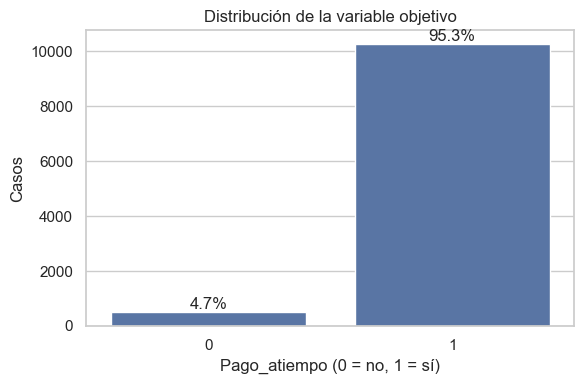

In [18]:
conteo = df[TARGET].value_counts().sort_index()
pct = df[TARGET].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"casos": conteo, "%": pct}))
print(f"Razón de desbalance (mayoritaria / minoritaria): {conteo.max() / conteo.min():.1f} : 1")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x=TARGET, ax=ax)
ax.set(title="Distribución de la variable objetivo", xlabel="Pago_atiempo (0 = no, 1 = sí)", ylabel="Casos")
for p, v in zip(ax.patches, pct):
    ax.annotate(f"{v:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Lectura.** El **95.2 %** de los créditos se paga a tiempo y solo el **4.8 % (511 casos)** no. El desbalance es de ~20 a 1. Consecuencias:

- La **exactitud (accuracy) no sirve** como métrica: un modelo que siempre prediga "paga" acierta 95 %. Hay que usar AUC-ROC / AUC-PR, recall y precisión de la clase 0, F1 o KS.
- Hay que usar **validación estratificada** y valorar técnicas de balanceo (pesos de clase, submuestreo/sobremuestreo) o ajuste del umbral de decisión.
- Con solo 511 casos de la clase de interés, los modelos muy complejos corren riesgo de sobreajuste.

### 5.2 Variables numéricas

Descriptivos tras corregir los tipos. Además del `describe()` se calculan: rango, IQR, varianza, coeficiente de variación, asimetría (*skewness*), curtosis, % de ceros, % de outliers por la regla 1.5·IQR y una clasificación heurística del tipo de distribución.

In [19]:
df[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80"
plazo_meses,"10,762.00",10.57,6.59,2.00,6.00,10.00,12.00,48.00
edad_cliente,"10,613.00",42.85,11.95,19.00,33.00,42.00,52.00,69.00
salario_cliente,"10,658.00","4,118,092.90","5,103,325.02","243,798.00","2,000,000.00","3,000,000.00","4,765,250.00","95,985,077.00"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00"
puntaje,"10,763.00",91.17,16.47,-38.01,95.23,95.23,95.23,95.23
puntaje_datacredito,"10,611.00",791.53,51.43,7.00,758.00,792.00,826.00,999.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00


In [20]:
def tipo_distribucion(s: pd.Series) -> str:
    """Clasificación heurística a partir de asimetría, curtosis y concentración de valores."""
    s = s.dropna()
    dominante = s.value_counts(normalize=True).iloc[0]
    if dominante >= 0.80:
        return "Cuasi-constante (un valor domina)"
    base = "discreta" if s.nunique() <= 40 else "continua"
    sk, ku = s.skew(), s.kurt()
    if abs(sk) < 0.3 and ku < -1:
        forma = "uniforme"
    elif abs(sk) < 0.5 and abs(ku) < 1:
        forma = "aprox. gaussiana"
    elif sk >= 1 and s.min() >= 0:
        forma = "sesgada a la derecha (cola larga / log-normal)"
    elif sk <= -1:
        forma = "sesgada a la izquierda (con tope superior)"
    else:
        forma = "moderadamente asimétrica"
    return f"{base}, {forma}"


def pct_outliers(s: pd.Series) -> float:
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return 100 * ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()


def descriptivos(datos: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    filas = {}
    for c in cols:
        s = datos[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        filas[c] = {
            "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
            "mín": s.min(), "máx": s.max(), "rango": s.max() - s.min(),
            "Q1": q1, "Q3": q3, "IQR": q3 - q1,
            "varianza": s.var(), "desv_est": s.std(),
            "coef_var": s.std() / s.mean() if s.mean() else np.nan,
            "skewness": s.skew(), "kurtosis": s.kurt(),
            "% ceros": 100 * (s == 0).mean(), "% outliers": pct_outliers(s),
            "distribución": tipo_distribucion(s),
        }
    return pd.DataFrame(filas).T


desc = descriptivos(df, NUMERICAS)
pd.set_option("display.float_format", "{:,.2f}".format)
desc[["media", "mediana", "moda", "mín", "máx", "rango"]]

,media,mediana,moda,mín,máx,rango
capital_prestado,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","41,084,152.80"
plazo_meses,10.57,10.00,6.00,2.00,48.00,46.00
edad_cliente,42.85,42.00,40.00,19.00,69.00,50.00
salario_cliente,"4,118,092.90","3,000,000.00","3,000,000.00","243,798.00","95,985,077.00","95,741,279.00"
total_otros_prestamos,"6,238,869.65","1,000,000.00",2000000,0,6787675263,6787675263
cuota_pactada,"243,617.41","182,863.00",205990,23944,3816752,3792808
puntaje,91.17,95.23,95.23,-38.01,95.23,133.24
puntaje_datacredito,791.53,792.00,783.00,7.00,999.00,992.00
cant_creditosvigentes,5.73,5.00,4,0,62,62
huella_consulta,4.23,4.00,2,0,29,29


In [21]:
desc[["Q1", "Q3", "IQR", "varianza", "desv_est", "coef_var", "skewness", "kurtosis", "% ceros", "% outliers", "distribución"]]

,Q1,Q3,IQR,varianza,desv_est,coef_var,skewness,kurtosis,% ceros,% outliers,distribución
capital_prestado,"1,224,831.00","3,084,840.00","1,860,009.00","3,646,735,466,988.66","1,909,642.76",0.78,3.72,35.32,0.00,5.11,"continua, sesgada a la derecha (cola larga / l..."
plazo_meses,6.00,12.00,6.00,43.40,6.59,0.62,2.35,6.12,0.00,8.07,"discreta, sesgada a la derecha (cola larga / l..."
edad_cliente,33.00,52.00,19.00,142.74,11.95,0.28,0.27,-0.86,0.00,0.00,"continua, aprox. gaussiana"
salario_cliente,"2,000,000.00","4,765,250.00","2,765,250.00","26,043,926,263,819.14","5,103,325.02",1.24,8.68,113.16,0.00,6.59,"continua, sesgada a la derecha (cola larga / l..."
total_otros_prestamos,"500,000.00","2,000,000.00","1,500,000.00","14,022,897,787,155,478.00","118,418,316.94",18.98,38.46,"1,719.28",4.13,5.47,"continua, sesgada a la derecha (cola larga / l..."
cuota_pactada,"121,041.50","287,833.50","166,792.00","44,307,595,469.58","210,493.69",0.86,3.79,26.65,0.00,7.11,"continua, sesgada a la derecha (cola larga / l..."
puntaje,95.23,95.23,0.00,271.11,16.47,0.18,-4.87,24.08,0.00,12.60,Cuasi-constante (un valor domina)
puntaje_datacredito,758.00,826.00,68.00,"2,645.35",51.43,0.06,-0.99,9.98,0.00,0.47,"continua, moderadamente asimétrica"
cant_creditosvigentes,3.00,8.00,5.00,15.82,3.98,0.69,1.80,8.62,3.76,2.25,"discreta, sesgada a la derecha (cola larga / l..."
huella_consulta,2.00,6.00,4.00,9.39,3.06,0.72,1.49,4.00,6.50,2.01,"discreta, sesgada a la derecha (cola larga / l..."


**Interpretación del describe y de los descriptivos.**

- **Montos (`capital_prestado`, `cuota_pactada`, `salario_cliente`, `total_otros_prestamos`, `promedio_ingresos_datacredito`, `saldo_total`, `saldo_mora`):** la **media está muy por encima de la mediana** y la asimetría es alta y positiva → distribuciones de **cola larga a la derecha, tipo log-normal**. Es lo típico del dinero: muchos créditos pequeños y pocos muy grandes. Mediana ≈ 1.9 M de capital y ≈ 183 mil de cuota, con máximos 20 veces mayores. Los coeficientes de variación (> 1 en varias) confirman la fuerte dispersión.
- **`total_otros_prestamos` y `saldo_mora`:** la asimetría y la curtosis son extremas (miles de unidades); unos pocos registros dominan la media. Se necesita transformación logarítmica o *winsorizing*.
- **`saldo_mora`:** ~98 % de ceros → **cuasi-constante**; su información está en los pocos casos distintos de cero (se verá que son muy relevantes).
- **`puntaje`:** distribución **sesgada a la izquierda con tope**: ~87 % de las filas tiene exactamente 95.23 (el máximo), y los valores bajos (incluso negativos) forman la cola. Es una variable "saturada".
- **`puntaje_datacredito`:** moderadamente sesgada a la izquierda (asimetría ≈ −1) con colas pesadas (curtosis ≈ 10); el grueso está entre 700 y 900 (mediana 792).
- **`edad_cliente`:** es la **única variable aproximadamente gaussiana** (asimetría 0.27, curtosis −0.86; media 42.9 ≈ mediana 42; rango 19–69 años tras anular valores imposibles).
- **`plazo_meses`:** discreta y multimodal, con picos en **6, 12 y 10 meses** (6 y 12 reúnen ≈ 55 % de los créditos); casi una variable categórica.
- **Conteos (`cant_creditosvigentes`, `huella_consulta`, `creditos_sector*`):** enteros pequeños con sesgo positivo, típicos de una distribución de Poisson/binomial negativa; `creditos_sectorCooperativo` tiene 82 % de ceros.
- **Salvo `edad_cliente`, ninguna variable es gaussiana, y ninguna es uniforme.** Eso importa: los modelos lineales/de distancia necesitarán transformar y escalar; los modelos de árboles (XGBoost, Random Forest) son robustos a estas formas.

#### Histogramas

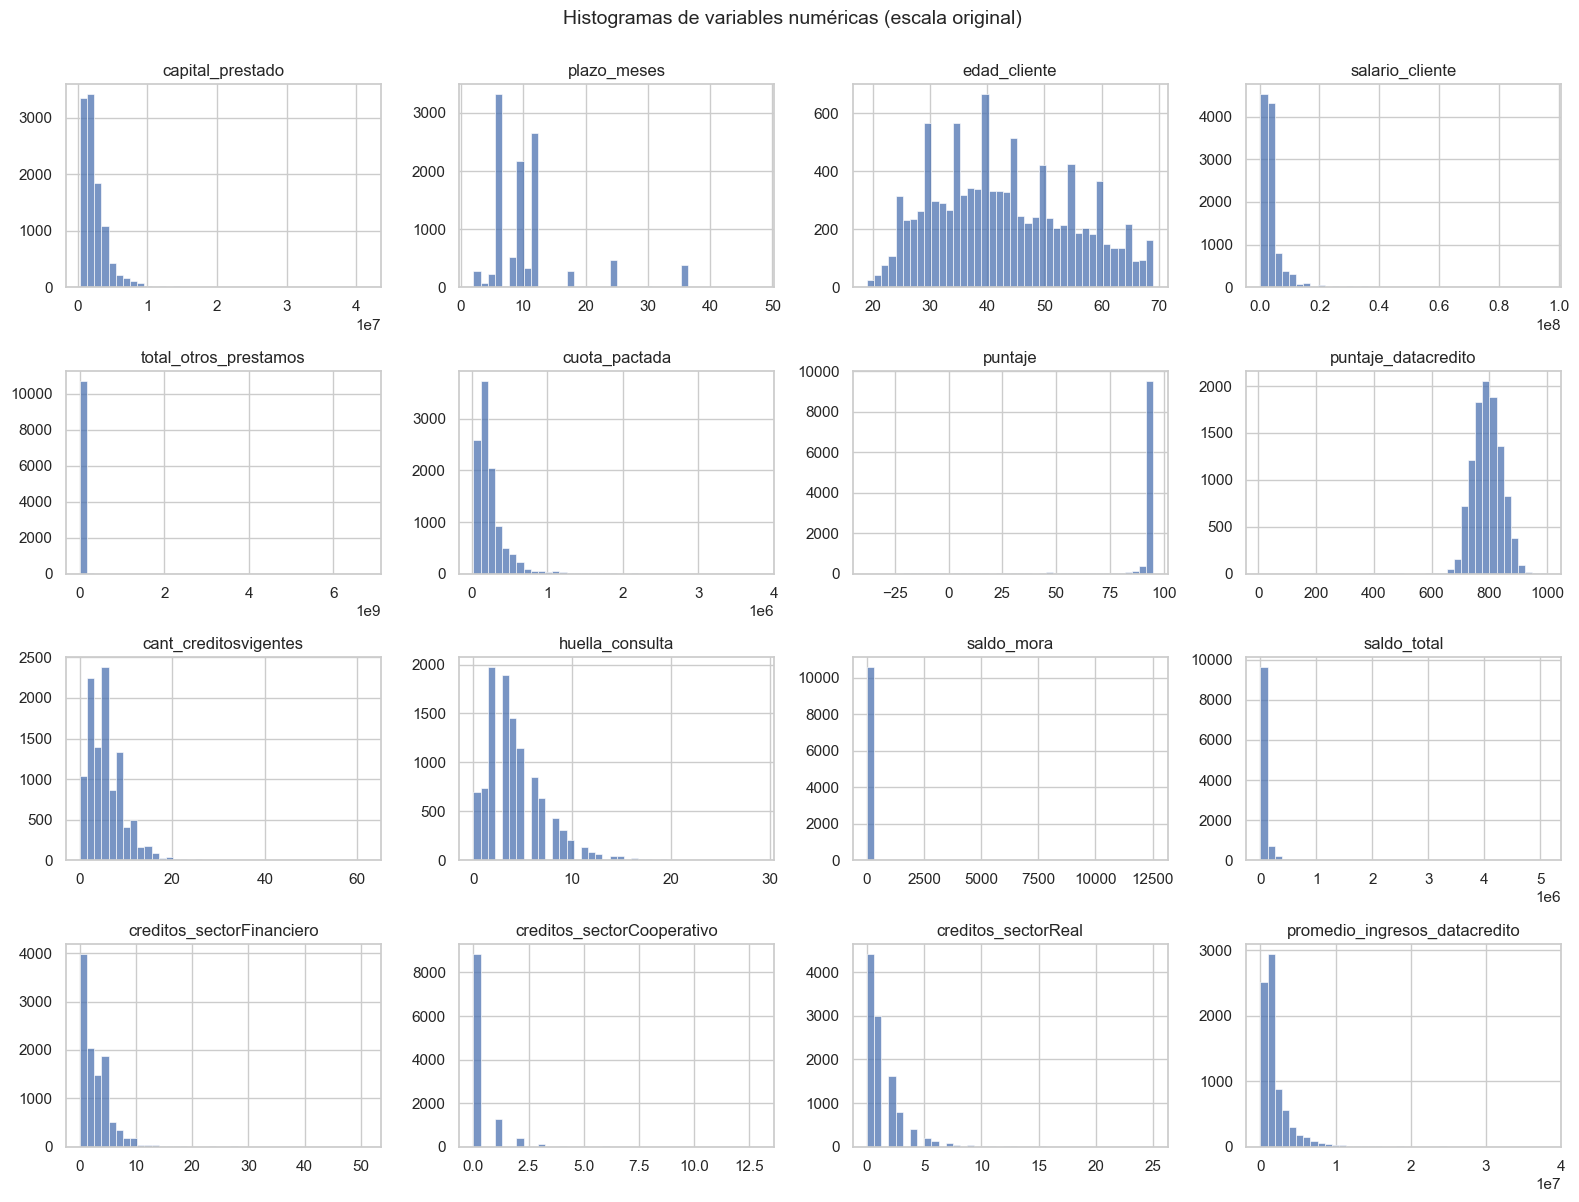

In [22]:
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4 * n_cols, 3 * n_filas))
for ax, col in zip(axes.flat, NUMERICAS):
    sns.histplot(df[col].dropna(), bins=40, ax=ax)
    ax.set(title=col, xlabel="", ylabel="")
for ax in axes.flat[len(NUMERICAS):]:
    ax.remove()
fig.suptitle("Histogramas de variables numéricas (escala original)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

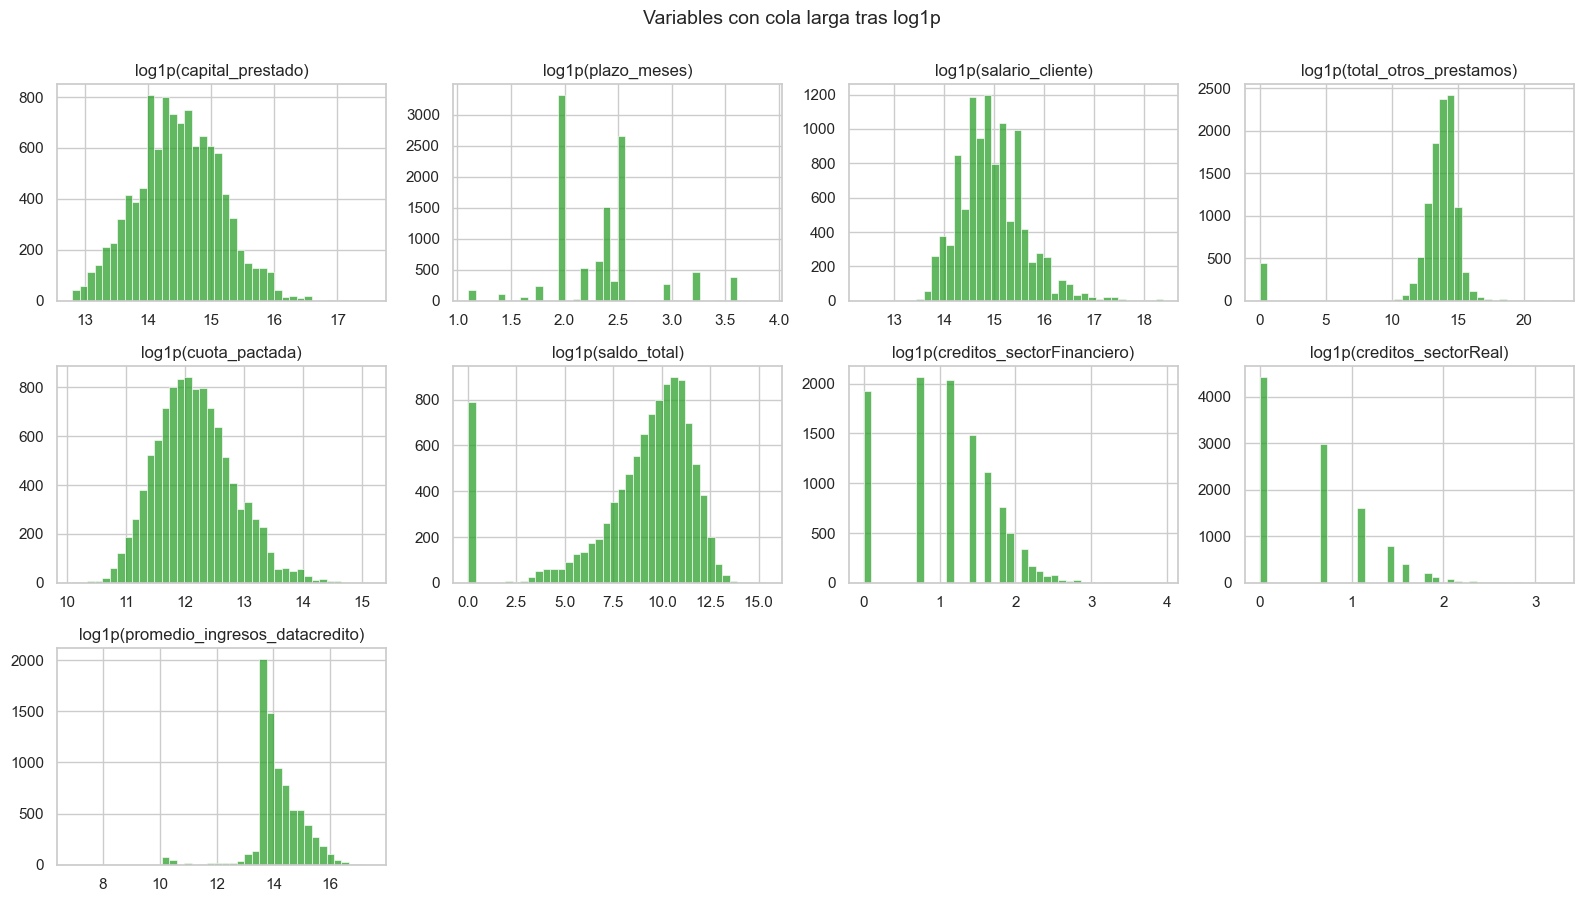

In [23]:
# Las variables con cola larga se ven apretadas a la izquierda: se repite con log1p para ver su forma real
sesgadas = desc.index[(desc["skewness"] > 2) & (desc["mín"] >= 0) & (desc["% ceros"] < 80)].tolist()
n_filas_s = int(np.ceil(len(sesgadas) / n_cols))
fig, axes = plt.subplots(n_filas_s, n_cols, figsize=(4 * n_cols, 3 * n_filas_s))
for ax, col in zip(np.atleast_1d(axes).flat, sesgadas):
    sns.histplot(np.log1p(df[col].dropna()), bins=40, ax=ax, color="tab:green")
    ax.set(title=f"log1p({col})", xlabel="", ylabel="")
for ax in np.atleast_1d(axes).flat[len(sesgadas):]:
    ax.remove()
fig.suptitle("Variables con cola larga tras log1p", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

**Lectura.** En escala original casi todos los montos son una barra pegada al origen con una cola interminable. Tras `log1p` pasan a una campana mucho más simétrica: confirma que son **aproximadamente log-normales** y que la transformación logarítmica es la adecuada. `salario_cliente` y `total_otros_prestamos` muestran además picos en valores "redondos" (1 M, 2 M, 3 M…): el cliente **declara** montos aproximados.

#### Boxplots y valores atípicos

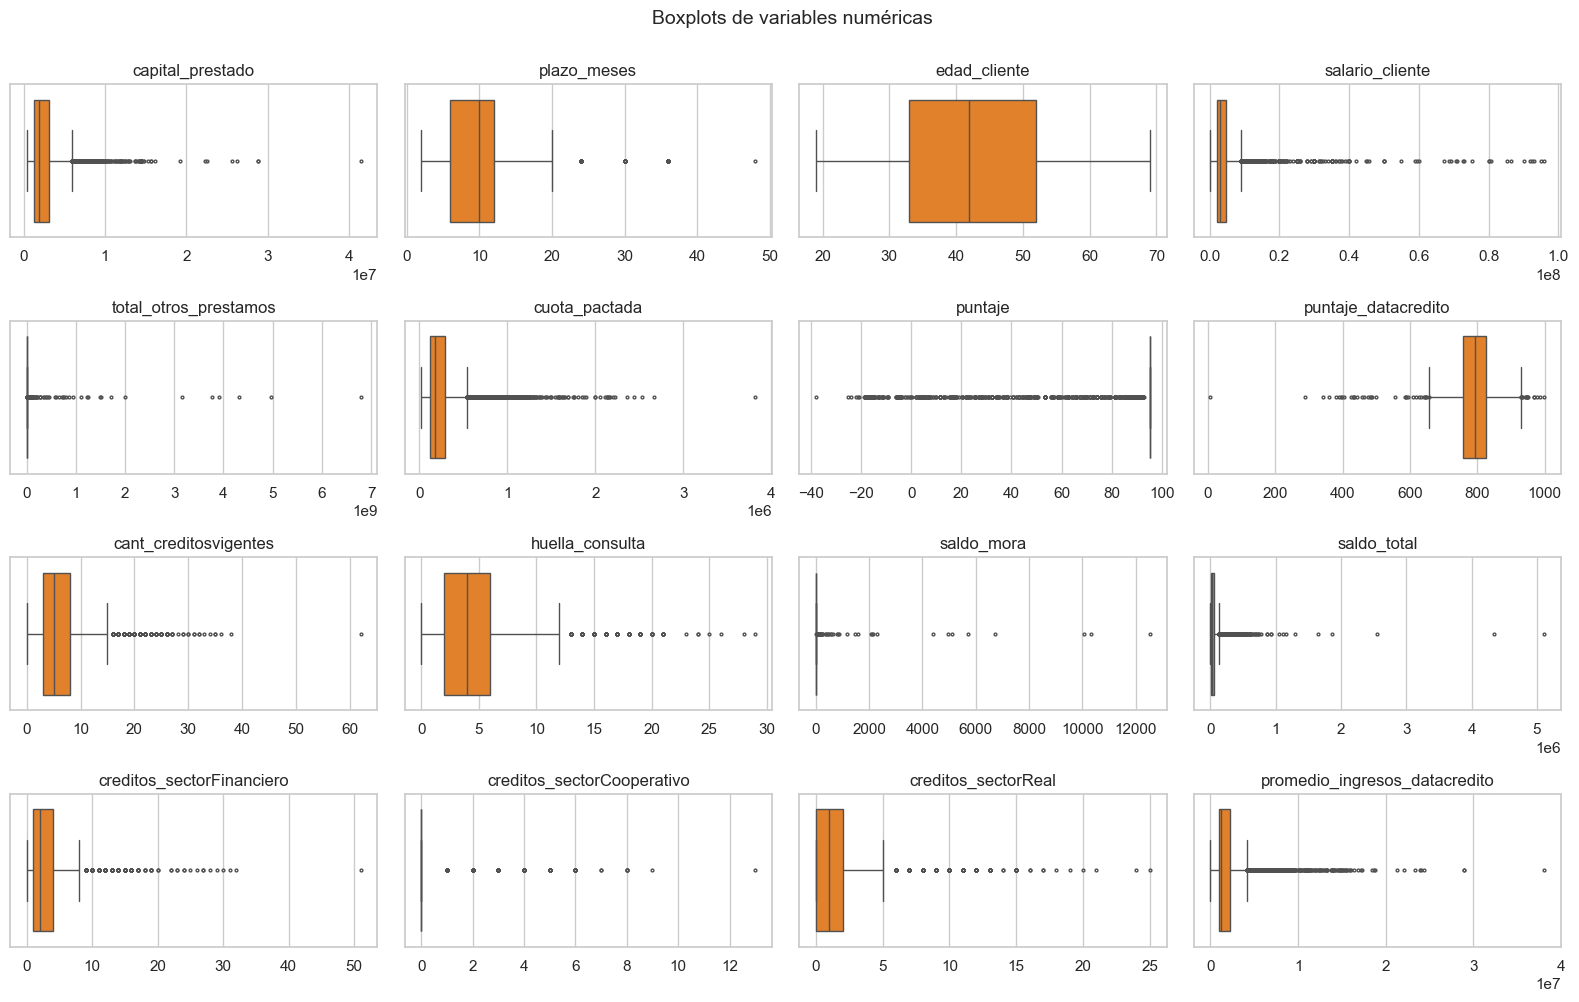

In [24]:
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4 * n_cols, 2.5 * n_filas))
for ax, col in zip(axes.flat, NUMERICAS):
    sns.boxplot(x=df[col], ax=ax, color="tab:orange", fliersize=2)
    ax.set(title=col, xlabel="")
for ax in axes.flat[len(NUMERICAS):]:
    ax.remove()
fig.suptitle("Boxplots de variables numéricas", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

In [25]:
desc[["% outliers", "skewness", "kurtosis"]].astype(float).sort_values("% outliers", ascending=False)

,% outliers,skewness,kurtosis
creditos_sectorCooperativo,17.61,4.22,29.35
puntaje,12.60,-4.87,24.08
promedio_ingresos_datacredito,10.01,4.28,32.78
saldo_total,9.14,20.20,789.17
plazo_meses,8.07,2.35,6.12
cuota_pactada,7.11,3.79,26.65
salario_cliente,6.59,8.68,113.16
total_otros_prestamos,5.47,38.46,"1,719.28"
capital_prestado,5.11,3.72,35.32
creditos_sectorFinanciero,3.38,2.70,19.44


**Lectura.** Las variables de monto tienen entre **5 % y 10 % de valores marcados como atípicos** por la regla 1.5·IQR (capital 5.1 %, cuota 7.1 %, salario 6.6 %, saldo_total 9.1 %, ingresos de la central 10 %), y `puntaje` un 12.6 % en su cola inferior. En `creditos_sectorCooperativo` (17.6 %) y `saldo_mora` el IQR es 0, así que la regla marca cualquier valor distinto de cero: ese porcentaje no es informativo. `edad_cliente` no tiene atípicos. Los "outliers" aquí **no son necesariamente errores**: en variables monetarias de cola larga son clientes legítimamente grandes. Los realmente erróneos (salarios de miles de millones, edad 122) ya se anularon en la sección 2. Para el resto la recomendación es *transformar o recortar* (percentiles 1–99) en vez de eliminar filas, porque con solo 511 casos de la clase 0 no conviene perder observaciones. Las variables de conteo con muchos "outliers" (p. ej. `huella_consulta`) solo tienen cola derecha natural.

#### Tablas pivote: perfil de las variables numéricas por segmento

In [26]:
pd.pivot_table(df, values=["capital_prestado", "cuota_pactada", "salario_cliente", "edad_cliente",
                           "plazo_meses", "puntaje_datacredito", "huella_consulta"],
               index="tipo_laboral", aggfunc=["median", "mean"], observed=True).T

tipo_laboral                   Empleado  Independiente
median capital_prestado    1,951,365.00   1,872,000.00
       cuota_pactada         173,304.00     206,818.00
       edad_cliente               40.00          45.00
       huella_consulta             4.00           4.00
       plazo_meses                10.00           8.00
       puntaje_datacredito       790.00         794.00
       salario_cliente     2,633,000.00   3,800,000.00
mean   capital_prestado    2,394,980.42   2,500,582.34
       cuota_pactada         222,471.96     279,241.34
       edad_cliente               41.51          45.04
       huella_consulta             4.21           4.26
       plazo_meses                11.40           9.16
       puntaje_datacredito       790.59         793.09
       salario_cliente     3,734,574.07   4,759,277.93

**Lectura.** Los **independientes** piden un capital similar al de los empleados (mediana ≈ 1.9 M) pero con **plazos más cortos (8 vs 10 meses) y por tanto cuotas más altas (≈ 207 mil vs 173 mil)**; además declaran salarios mayores (mediana 3.8 M vs 2.6 M) y son mayores (45 vs 40 años). Medianas (robustas) y medias (sensibles a extremos) difieren más en los montos.

### 5.3 Variables categóricas

In [27]:
for col in CATEGORICAS:
    t = df_cat[col].value_counts().to_frame("casos").assign(pct=lambda x: (100 * x["casos"] / len(df_cat)).round(2))
    print(f"--- {col} ---")
    display(t)

--- tipo_credito ---


,casos,pct
tipo_credito,,
4,7747,71.98
9,2876,26.72
10,116,1.08
6,21,0.20
7,2,0.02
68,1,0.01


--- tipo_laboral ---


,casos,pct
tipo_laboral,,
Empleado,6754,62.75
Independiente,4009,37.25


--- tendencia_ingresos ---


,casos,pct
tendencia_ingresos,,
Creciente,5294,49.19
Sin dato,2990,27.78
Decreciente,1291,11.99
Estable,1188,11.04


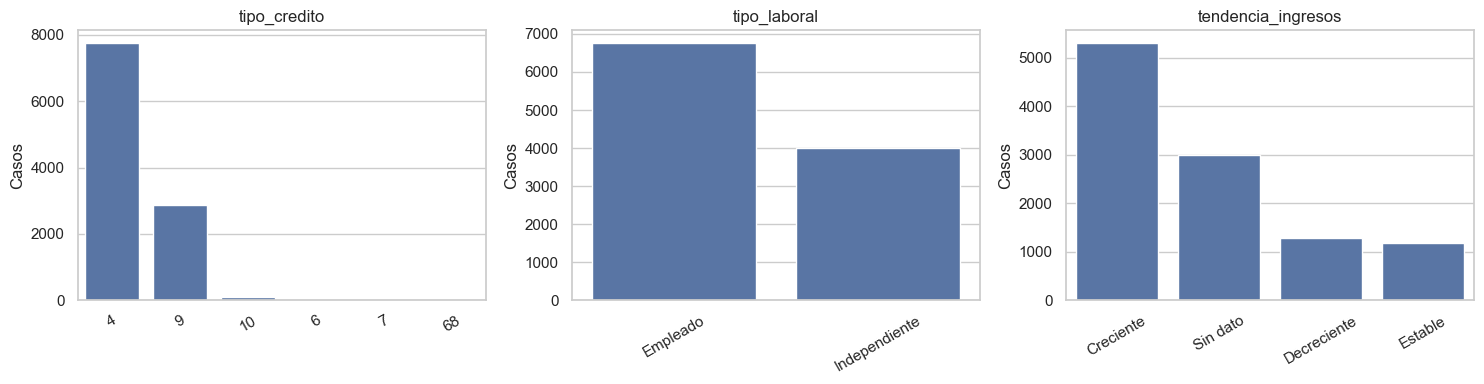

In [28]:
fig, axes = plt.subplots(1, len(CATEGORICAS), figsize=(5 * len(CATEGORICAS), 4))
for ax, col in zip(axes, CATEGORICAS):
    orden = df_cat[col].value_counts().index
    sns.countplot(data=df_cat, x=col, order=orden, ax=ax)
    ax.set(title=col, xlabel="", ylabel="Casos")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Interpretación.**

- **`tipo_credito`:** dominado por los códigos **4 (72 %) y 9 (27 %)**; los códigos 10 (1 %), 6 (21 filas), 7 (2 filas) y 68 (1 fila) son prácticamente raros. Una variable con categorías tan poco pobladas no es fiable para estimar efectos: se recomienda **agrupar las categorías con menos de ~1 % en "Otros"**.
- **`tipo_laboral`:** dicotómica y razonablemente balanceada (63 % empleados, 37 % independientes).
- **`tendencia_ingresos`:** "Creciente" es la mayoritaria (49 %), "Decreciente" 12 % y "Estable" 11 %; **un 28 % queda "Sin dato"** (ingresos sin historial en la central), un grupo demasiado grande para descartarlo. El vacío afecta mucho más a los **independientes (41.5 %) que a los empleados (19.7 %)**: la central registra mejor el ingreso formal.

In [29]:
# Tabla cruzada entre las dos categóricas principales (conteos y % por fila)
cruce = pd.crosstab(df_cat["tipo_laboral"], df_cat["tendencia_ingresos"])
display(cruce)
display((pd.crosstab(df_cat["tipo_laboral"], df_cat["tendencia_ingresos"], normalize="index") * 100).round(1))

tendencia_ingresos,Creciente,Decreciente,Estable,Sin dato
tipo_laboral,,,,
Empleado,3843,937,646,1328
Independiente,1451,354,542,1662


tendencia_ingresos,Creciente,Decreciente,Estable,Sin dato
tipo_laboral,,,,
Empleado,56.90,13.90,9.60,19.70
Independiente,36.20,8.80,13.50,41.50


### 5.4 Variable de fecha: `fecha_prestamo`

Rango: 2024-11-26 → 2026-04-26
¿Datos ordenados por fecha? False


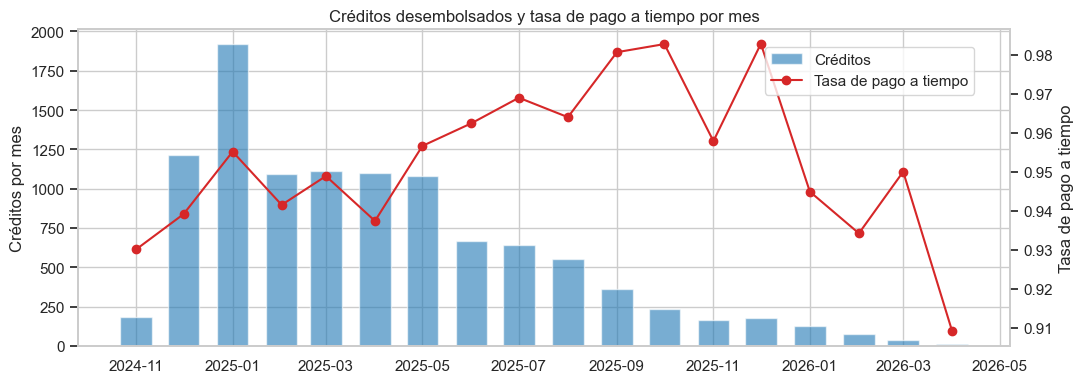

fecha_prestamo,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01
créditos,186.00,"1,216.00","1,917.00","1,094.00","1,115.00","1,102.00","1,083.00",665.00,644.00,555.00,361.00,231.00,166.00,174.00,127.00,76.00,40.00,11.00
tasa_pago_atiempo,0.93,0.94,0.95,0.94,0.95,0.94,0.96,0.96,0.97,0.96,0.98,0.98,0.96,0.98,0.94,0.93,0.95,0.91


In [30]:
print("Rango:", df["fecha_prestamo"].min().date(), "→", df["fecha_prestamo"].max().date())
print("¿Datos ordenados por fecha?", df["fecha_prestamo"].is_monotonic_increasing)

por_mes = (
    df.set_index("fecha_prestamo")
    .resample("MS")[TARGET]
    .agg(["count", "mean"])
    .rename(columns={"count": "créditos", "mean": "tasa_pago_atiempo"})
)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(por_mes.index, por_mes["créditos"], width=20, color="tab:blue", alpha=0.6, label="Créditos")
ax1.set_ylabel("Créditos por mes")
ax2 = ax1.twinx()
ax2.plot(por_mes.index, por_mes["tasa_pago_atiempo"], color="tab:red", marker="o", label="Tasa de pago a tiempo")
ax2.set_ylabel("Tasa de pago a tiempo")
ax2.grid(False)
ax1.set_title("Créditos desembolsados y tasa de pago a tiempo por mes")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.show()
por_mes.T.round(3)

**Lectura.**

- El volumen **cae con fuerza**: ~1 900 créditos en enero de 2025, ~650 por mes a mitad de 2025 y menos de 250 por mes desde octubre de 2025 (solo 11 en abril de 2026). Hay muy pocos datos recientes.
- La **tasa de pago a tiempo sube con la fecha** (de ≈ 93–94 % a finales de 2024 hasta ≈ 98 % a finales de 2025). Probable explicación: los créditos recientes **aún no han tenido tiempo de caer en mora** (la etiqueta está "inmadura" o censurada), no que el comportamiento mejore. Hay que tenerlo presente porque sesga el aprendizaje del modelo.
- Los datos no están ordenados por fecha. Para validar el modelo conviene una **partición temporal** (entrenar con lo antiguo, probar con lo reciente) y analizar la madurez de la etiqueta antes de decidir el corte.

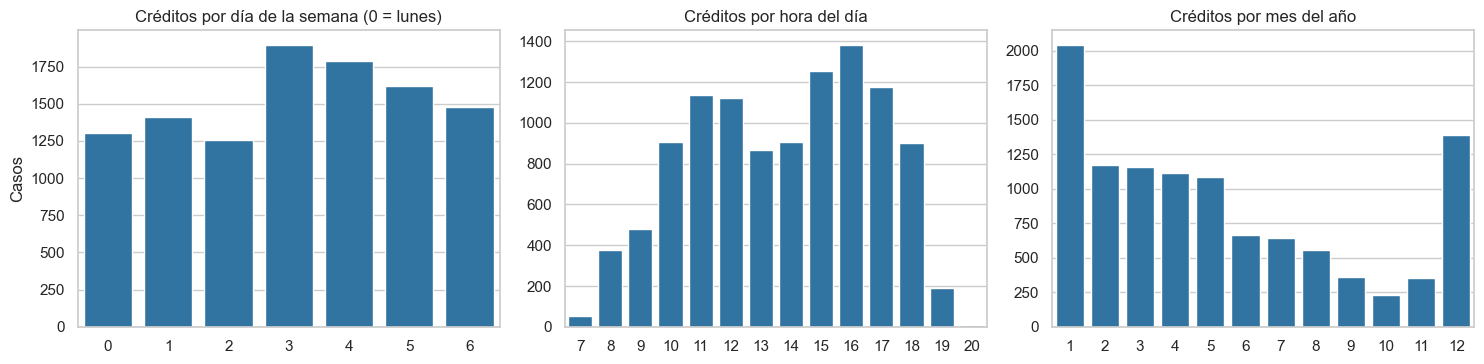

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
fechas = df["fecha_prestamo"]
sns.countplot(x=fechas.dt.dayofweek, ax=axes[0], color="tab:blue")
axes[0].set(title="Créditos por día de la semana (0 = lunes)", xlabel="", ylabel="Casos")
sns.countplot(x=fechas.dt.hour, ax=axes[1], color="tab:blue")
axes[1].set(title="Créditos por hora del día", xlabel="", ylabel="")
sns.countplot(x=fechas.dt.month, ax=axes[2], color="tab:blue")
axes[2].set(title="Créditos por mes del año", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

**Lectura.** Los desembolsos se concentran en horario de oficina (8 a.m.–6 p.m.) pero **se reparten por toda la semana**, incluidos sábados y domingos (≈ 29 % del total), con pico jueves–viernes. La distribución por mes refleja el volumen histórico más que estacionalidad real (solo ~18 meses de datos). Los créditos de fin de semana tienen una tasa de pago algo menor (≈ 93.7 % vs ≈ 96 %); se prueba como atributo en la sección 8.

## 6. Análisis bivariable frente a la variable objetivo
### 6.1 Numéricas vs `Pago_atiempo`

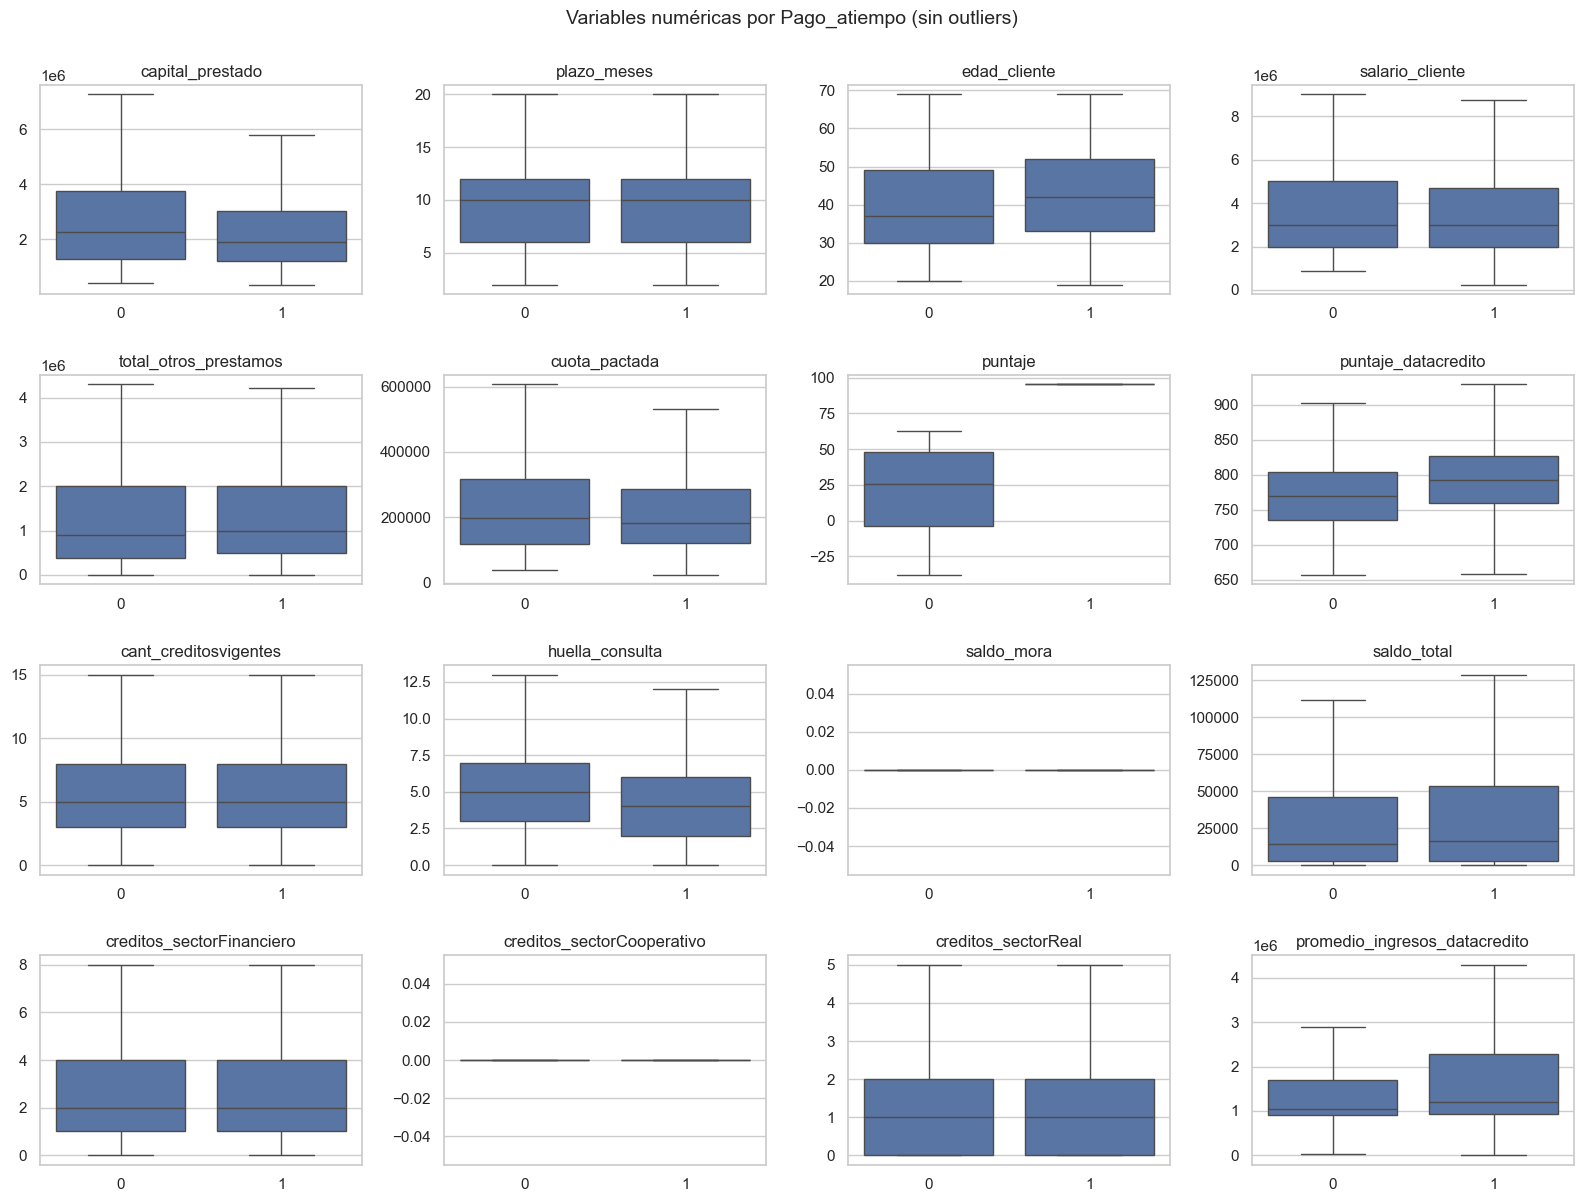

In [32]:
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4 * n_cols, 3 * n_filas))
for ax, col in zip(axes.flat, NUMERICAS):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, showfliers=False)
    ax.set(title=col, xlabel="", ylabel="")
for ax in axes.flat[len(NUMERICAS):]:
    ax.remove()
fig.suptitle("Variables numéricas por Pago_atiempo (sin outliers)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

In [33]:
resumen_bi = df.groupby(TARGET)[NUMERICAS].median().T
resumen_bi.columns = ["mediana_no_paga (0)", "mediana_paga (1)"]
resumen_bi["dif_relativa_%"] = 100 * (resumen_bi["mediana_paga (1)"] - resumen_bi["mediana_no_paga (0)"]) / resumen_bi["mediana_no_paga (0)"].abs().replace(0, np.nan)
resumen_bi["spearman_vs_objetivo"] = [df[c].corr(df[TARGET], method="spearman") for c in resumen_bi.index]
resumen_bi.sort_values("spearman_vs_objetivo", key=abs, ascending=False)

,mediana_no_paga (0),mediana_paga (1),dif_relativa_%,spearman_vs_objetivo
puntaje,25.42,95.23,274.63,0.64
saldo_mora,0.00,0.00,NaN,-0.11
puntaje_datacredito,769.00,792.00,2.99,0.09
huella_consulta,5.00,4.00,-20.00,-0.07
edad_cliente,37.00,42.00,13.51,0.06
promedio_ingresos_datacredito,"1,052,529.00","1,211,904.00",15.14,0.05
capital_prestado,"2,268,000.00","1,908,446.40",-15.85,-0.04
creditos_sectorFinanciero,2.00,2.00,0.00,0.03
total_otros_prestamos,"900,000.00","1,000,000.00",11.11,0.03
creditos_sectorCooperativo,0.00,0.00,NaN,0.02


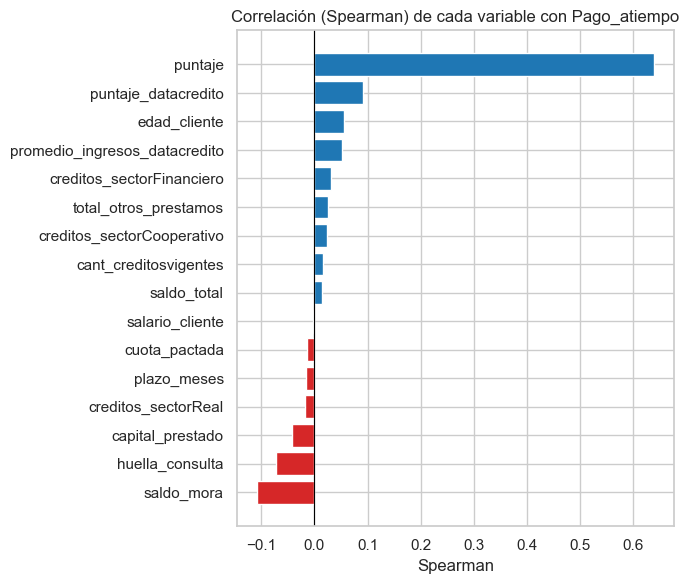

In [34]:
corr_target = resumen_bi["spearman_vs_objetivo"].sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr_target.index, corr_target.values, color=["tab:red" if v < 0 else "tab:blue" for v in corr_target])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Correlación (Spearman) de cada variable con Pago_atiempo", xlabel="Spearman")
plt.tight_layout()
plt.show()

**Interpretación.**

- **`puntaje` es, con enorme diferencia, la variable más asociada al objetivo (ρ ≈ 0.64)**; la siguiente es `saldo_mora` (ρ ≈ −0.11), seguida de `puntaje_datacredito` (+0.09) y `huella_consulta` (−0.07). El resto tiene |ρ| ≤ 0.06. Es decir: **ninguna variable tradicional del cliente tiene gran poder por sí sola**; las señales son débiles y se espera que el modelo dependa de combinaciones.
- A mayor **`puntaje_datacredito`**, más probabilidad de pagar (mediana 792 vs 769). A más **consultas recientes (`huella_consulta`)**, menor probabilidad: el cliente que busca crédito en muchos lados es más riesgoso.
- **`capital_prestado`**: quien no paga a tiempo tiene créditos algo mayores (mediana 2.27 M vs 1.91 M). `edad_cliente` y `promedio_ingresos_datacredito` se asocian positivamente (más edad e ingresos → mejor pago).
- Spearman es adecuado aquí porque el objetivo es binario y las distribuciones son sesgadas.

#### ¿Qué tasa de pago hay en cada tramo de las variables numéricas?

Una forma más intuitiva de leer la relación: dividir cada variable en cinco tramos de igual tamaño (quintiles) y ver cómo cambia la tasa de pago a tiempo. La línea punteada es la tasa global (95.2 %).

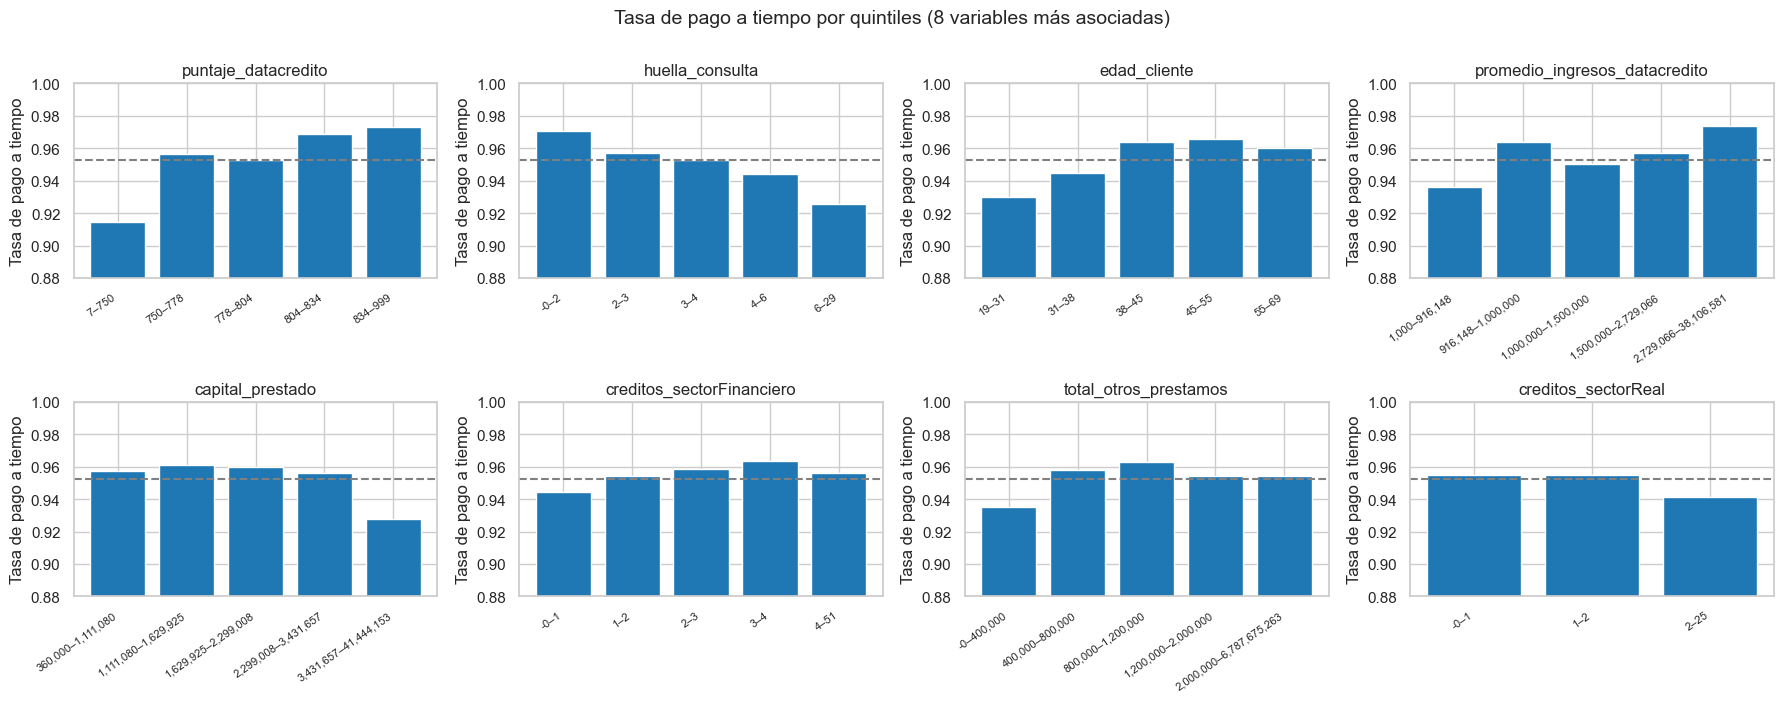

In [35]:
def tasa_por_cuantiles(col: str, q: int = 5) -> pd.DataFrame | None:
    s = df[col]
    try:
        tramos = pd.qcut(s, q, duplicates="drop")
    except ValueError:
        return None
    if tramos.cat.categories.size < 3:
        return None
    return df.groupby(tramos, observed=True)[TARGET].agg(casos="count", tasa="mean")


top = resumen_bi["spearman_vs_objetivo"].abs().sort_values(ascending=False).index
con_tramos = [c for c in top if tasa_por_cuantiles(c) is not None][:8]
tasa_global = df[TARGET].mean()

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, con_tramos):
    t = tasa_por_cuantiles(col)
    ax.bar(range(len(t)), t["tasa"], color="tab:blue")
    ax.axhline(tasa_global, ls="--", color="gray")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([f"{i.left:,.0f}–{i.right:,.0f}" for i in t.index], rotation=35, ha="right", fontsize=8)
    ax.set(title=col, ylim=(0.88, 1.0), ylabel="Tasa de pago a tiempo")
fig.suptitle("Tasa de pago a tiempo por quintiles (8 variables más asociadas)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

**Lectura.** El patrón es monótono en las variables de riesgo: la tasa de pago **baja a medida que aumentan las consultas (`huella_consulta`: ~97 % con pocas consultas frente a ~92.5 % con muchas)** y a medida que crece el **capital prestado** (el quintil más alto cae a ≈ 92.8 % frente a ≈ 96 % en los demás). Por edad los clientes jóvenes (≤ 30) pagan peor (≈ 92.9 %) que los de 40–70 (≈ 96 %). Son diferencias de 3 a 5 puntos porcentuales: pequeñas pero consistentes, sobre una base de 95 %.

#### Caso especial: `puntaje` (posible fuga de información)

,casos,tasa_pago_pct,no_pagan
puntaje,,,
≤ 0,135,0.00,135
0–50,291,0.00,291
50–90,618,86.20,85
90–95,312,100.00,0
tope (95.23),9407,100.00,0


Créditos con puntaje ≤ 50: 426  ->  tasa de pago 0.0%
Créditos con puntaje > 90: 9,719  ->  tasa de pago 100.0%
De los 511 que NO pagaron, 426 tienen puntaje ≤ 50


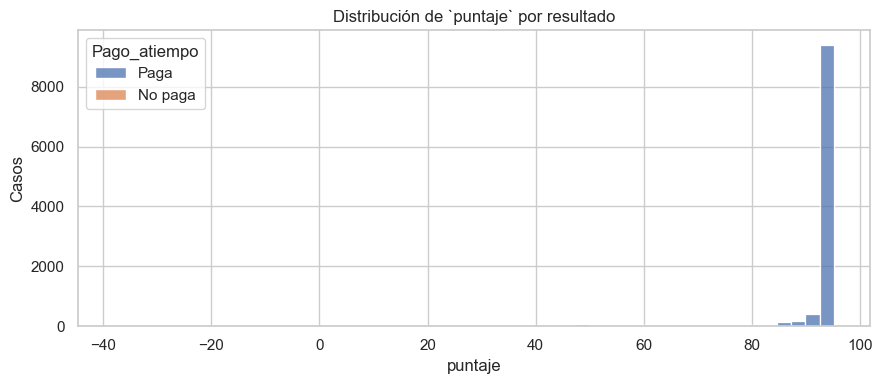

In [36]:
tramos_puntaje = pd.cut(df["puntaje"], [-100, 0, 50, 90, 95, 96],
                        labels=["≤ 0", "0–50", "50–90", "90–95", "tope (95.23)"])
t_p = df.groupby(tramos_puntaje, observed=True)[TARGET].agg(casos="count", tasa_pago_pct="mean", no_pagan=lambda s: int((s == 0).sum()))
t_p["tasa_pago_pct"] *= 100
display(t_p.round(1))

print(f"Créditos con puntaje ≤ 50: {(df['puntaje'] <= 50).sum():,}  ->  tasa de pago {df.loc[df['puntaje'] <= 50, TARGET].mean():.1%}")
print(f"Créditos con puntaje > 90: {(df['puntaje'] > 90).sum():,}  ->  tasa de pago {df.loc[df['puntaje'] > 90, TARGET].mean():.1%}")
print(f"De los {(df[TARGET] == 0).sum()} que NO pagaron, {(df.loc[df[TARGET] == 0, 'puntaje'] <= 50).sum()} tienen puntaje ≤ 50")

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="puntaje", hue=df[TARGET].map({0: "No paga", 1: "Paga"}), bins=50, multiple="stack", ax=ax)
ax.set(title="Distribución de `puntaje` por resultado", xlabel="puntaje", ylabel="Casos")
plt.tight_layout()
plt.show()

**Hallazgo crítico.**

- **Todos** los créditos con `puntaje ≤ 50` (426) **incumplieron**; **todos** con `puntaje > 90` (9 719) **pagaron**. Solo en el tramo intermedio (50–90, 618 créditos) hay mezcla. El 83 % de los incumplimientos (426 de 511) se explica con este único corte.
- Una relación tan perfecta es **sospechosa de fuga de información (*data leakage*)**: es probable que `puntaje` sea un puntaje interno calculado *después* del desembolso (o una función del comportamiento de pago) y por tanto **no esté disponible en el momento de decidir si se otorga el crédito**. Un modelo entrenado con él parecería excelente en validación y fallaría en producción.
- **Acción:** confirmar con el área de negocio cuándo se calcula `puntaje`. Si no existe al momento de originación, **debe excluirse del modelo**; si sí existe, el modelo debería evaluarse con y sin él (un modelo sin `puntaje` es el que realmente mide el aporte del resto de variables).

### 6.2 Categóricas vs `Pago_atiempo`

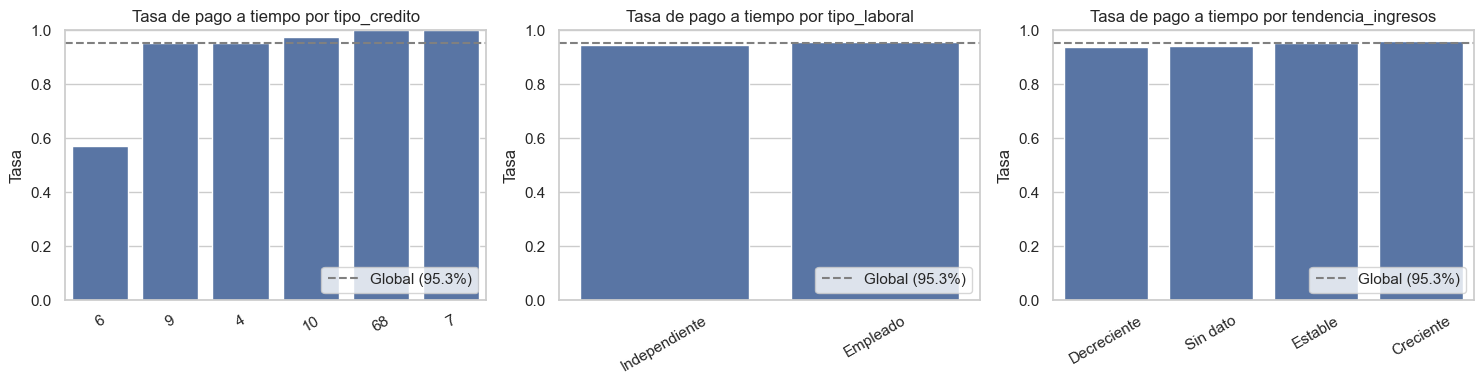

In [37]:
fig, axes = plt.subplots(1, len(CATEGORICAS), figsize=(5 * len(CATEGORICAS), 4))
for ax, col in zip(axes, CATEGORICAS):
    tasa = df_cat.groupby(col)[TARGET].mean().sort_values()
    sns.barplot(x=tasa.index.astype(str), y=tasa.values, order=tasa.index.astype(str), ax=ax)
    ax.axhline(tasa_global, ls="--", color="gray", label=f"Global ({tasa_global:.1%})")
    ax.set(title=f"Tasa de pago a tiempo por {col}", xlabel="", ylabel="Tasa", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [38]:
for col in CATEGORICAS:
    t = (df_cat.groupby(col)[TARGET]
         .agg(casos="count", tasa_pago_pct="mean", no_pagan=lambda s: int((s == 0).sum()))
         .assign(tasa_pago_pct=lambda x: 100 * x["tasa_pago_pct"])
         .assign(dif_vs_global_pp=lambda x: x["tasa_pago_pct"] - 100 * tasa_global)
         .sort_values("tasa_pago_pct"))
    print(f"--- {col} ---")
    display(t.round(1))

--- tipo_credito ---


,casos,tasa_pago_pct,no_pagan,dif_vs_global_pp
tipo_credito,,,,
6,21,57.10,9,-38.10
9,2876,95.30,136,0.00
4,7747,95.30,363,0.10
10,116,97.40,3,2.20
68,1,100.00,0,4.70
7,2,100.00,0,4.70


--- tipo_laboral ---


,casos,tasa_pago_pct,no_pagan,dif_vs_global_pp
tipo_laboral,,,,
Independiente,4009,94.50,221,-0.80
Empleado,6754,95.70,290,0.50


--- tendencia_ingresos ---


,casos,tasa_pago_pct,no_pagan,dif_vs_global_pp
tendencia_ingresos,,,,
Decreciente,1291,93.70,81,-1.50
Sin dato,2990,94.40,168,-0.90
Estable,1188,95.40,55,0.10
Creciente,5294,96.10,207,0.80


**Interpretación.**

- **`tipo_laboral`:** los empleados pagan mejor (95.7 %) que los independientes (94.5 %), una diferencia de ~1.2 pp. Efecto pequeño pero con muestra grande, por lo que es creíble.
- **`tendencia_ingresos`:** coherente con la lógica de negocio: **Creciente 96.1 % > Estable 95.4 % > Sin dato 94.4 % > Decreciente 93.7 %**. Los de ingresos decrecientes son el segmento más riesgoso conocido y "Sin dato" queda cerca de ese extremo (útil mantenerlo como categoría propia).
- **`tipo_credito`:** los códigos 4, 9 y 10 están entre 95 % y 97 %. El código 6 muestra solo 57 % de pago, pero con **21 casos**: esa cifra es muy inestable y no debe sobreinterpretarse. Es el argumento para agrupar categorías raras.

### 6.3 ¿Los nulos predicen el resultado?

In [39]:
filas = []
for col in df.columns[df.isna().any()]:
    nulo = df[col].isna()
    filas.append({"columna": col, "casos_nulo": int(nulo.sum()),
                  "pago_%_si_nulo": 100 * df.loc[nulo, TARGET].mean(),
                  "pago_%_si_dato": 100 * df.loc[~nulo, TARGET].mean()})
nulos_vs_target = pd.DataFrame(filas).set_index("columna")
nulos_vs_target["dif_pp"] = nulos_vs_target["pago_%_si_nulo"] - nulos_vs_target["pago_%_si_dato"]
nulos_vs_target.round(1)

,casos_nulo,pago_%_si_nulo,pago_%_si_dato,dif_pp
columna,,,,
plazo_meses,1,100.00,95.30,4.70
edad_cliente,150,92.70,95.30,-2.60
salario_cliente,105,94.30,95.30,-1.00
puntaje_datacredito,152,92.80,95.30,-2.50
saldo_mora,156,92.90,95.30,-2.30
saldo_total,156,92.90,95.30,-2.30
promedio_ingresos_datacredito,2937,94.30,95.60,-1.30
tendencia_ingresos,2990,94.40,95.60,-1.20


**Lectura.** **Todos los grupos con dato ausente pagan peor** que quienes sí lo tienen: sin ingresos/tendencia −1.2 a −1.3 pp; sin saldos −2.3 pp; sin `puntaje_datacredito` −2.5 pp; con `edad_cliente` anulada (casi todos eran la edad centinela 122) −2.6 pp. (`plazo_meses` tiene 1 caso: no interpretable.) La ausencia de dato **sí contiene información** → al imputar hay que añadir indicadores de nulo.

## 7. Análisis multivariable
### 7.1 Matriz de correlación

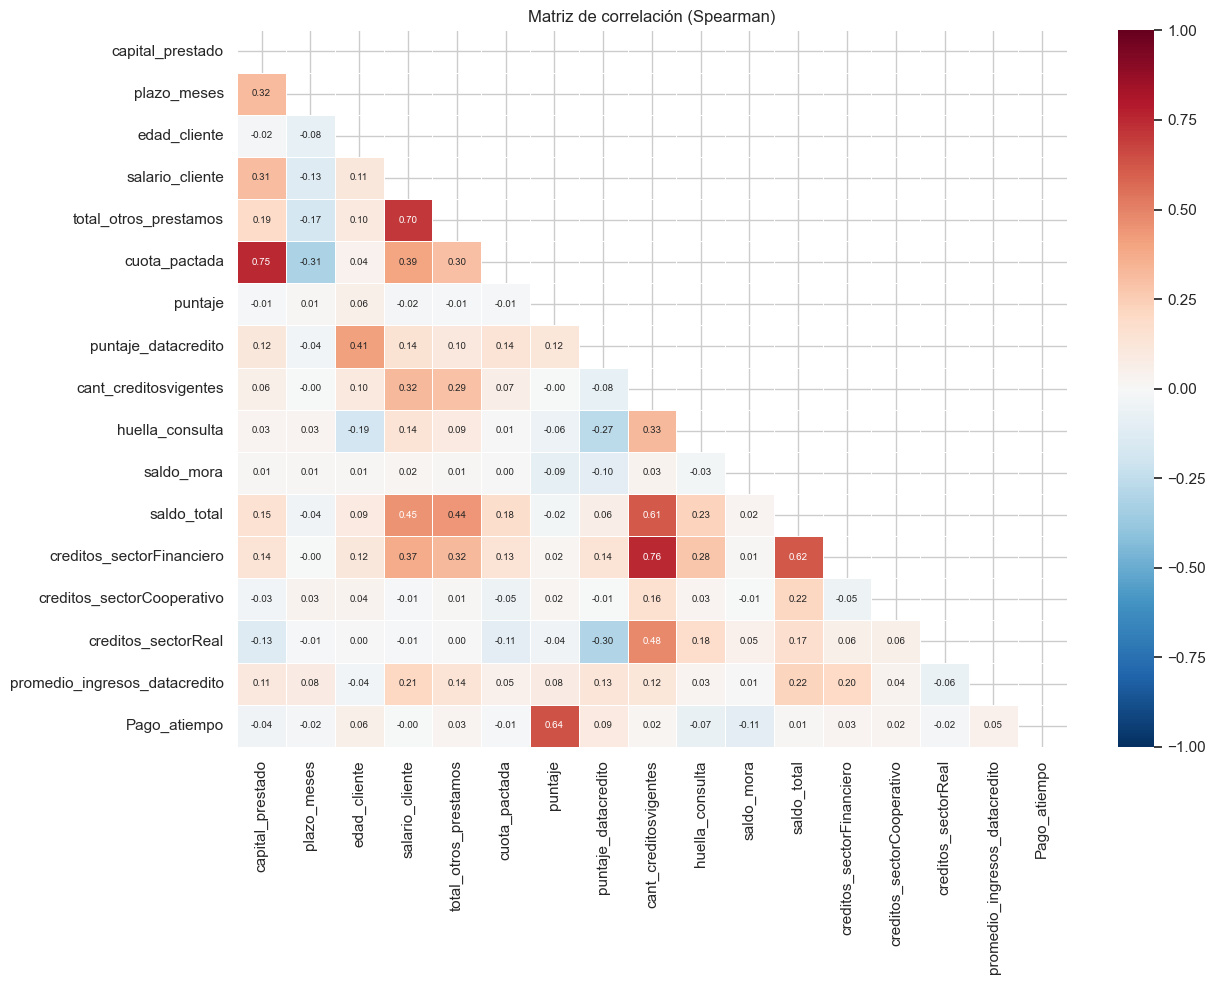

In [40]:
corr = df[NUMERICAS + [TARGET]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, ax=ax)
ax.set_title("Matriz de correlación (Spearman)")
plt.tight_layout()
plt.show()

In [41]:
# Pares de variables explicativas muy correlacionadas (posible redundancia / multicolinealidad)
pares = (
    corr.drop(index=TARGET, columns=TARGET)
    .where(np.triu(np.ones(corr.shape[0] - 1, dtype=bool), k=1))
    .stack()
    .rename("spearman")
    .loc[lambda s: s.abs() >= 0.5]
    .sort_values(key=abs, ascending=False)
)
pares.to_frame()

,,spearman
cant_creditosvigentes,creditos_sectorFinanciero,0.76
capital_prestado,cuota_pactada,0.75
salario_cliente,total_otros_prestamos,0.70
saldo_total,creditos_sectorFinanciero,0.62
cant_creditosvigentes,saldo_total,0.61


**Interpretación.**

- Las correlaciones fuertes tienen explicación de negocio: **`capital_prestado` ↔ `cuota_pactada`** (a mayor crédito, mayor cuota); **`cant_creditosvigentes` ↔ `creditos_sectorFinanciero`** (la mayoría de los créditos vigentes son del sector financiero y los sectores suman parte del total); **`salario_cliente` ↔ `total_otros_prestamos`** (quien más gana, más se endeuda); y `saldo_total` con los créditos vigentes y el sector financiero.
- Ya se eliminó `saldo_principal` (ρ = 0.95 con `saldo_total`). Las parejas restantes están entre 0.6 y 0.76: son redundancias parciales; no obligan a eliminar variables, pero aconsejan regularización o modelos de árboles, y justifican crear **razones** (cuota/salario, etc.) que resumen la relación (sección 8).
- La fila inferior confirma que, salvo `puntaje`, **el objetivo apenas se correlaciona linealmente con las demás**: el poder predictivo vendrá de combinaciones no lineales.

### 7.2 Pairplot de variables clave
Se usa una muestra que incluye **todos** los casos de la clase 0 y una muestra aleatoria de la clase 1 (para que los incumplimientos sean visibles), con los montos en escala logarítmica.

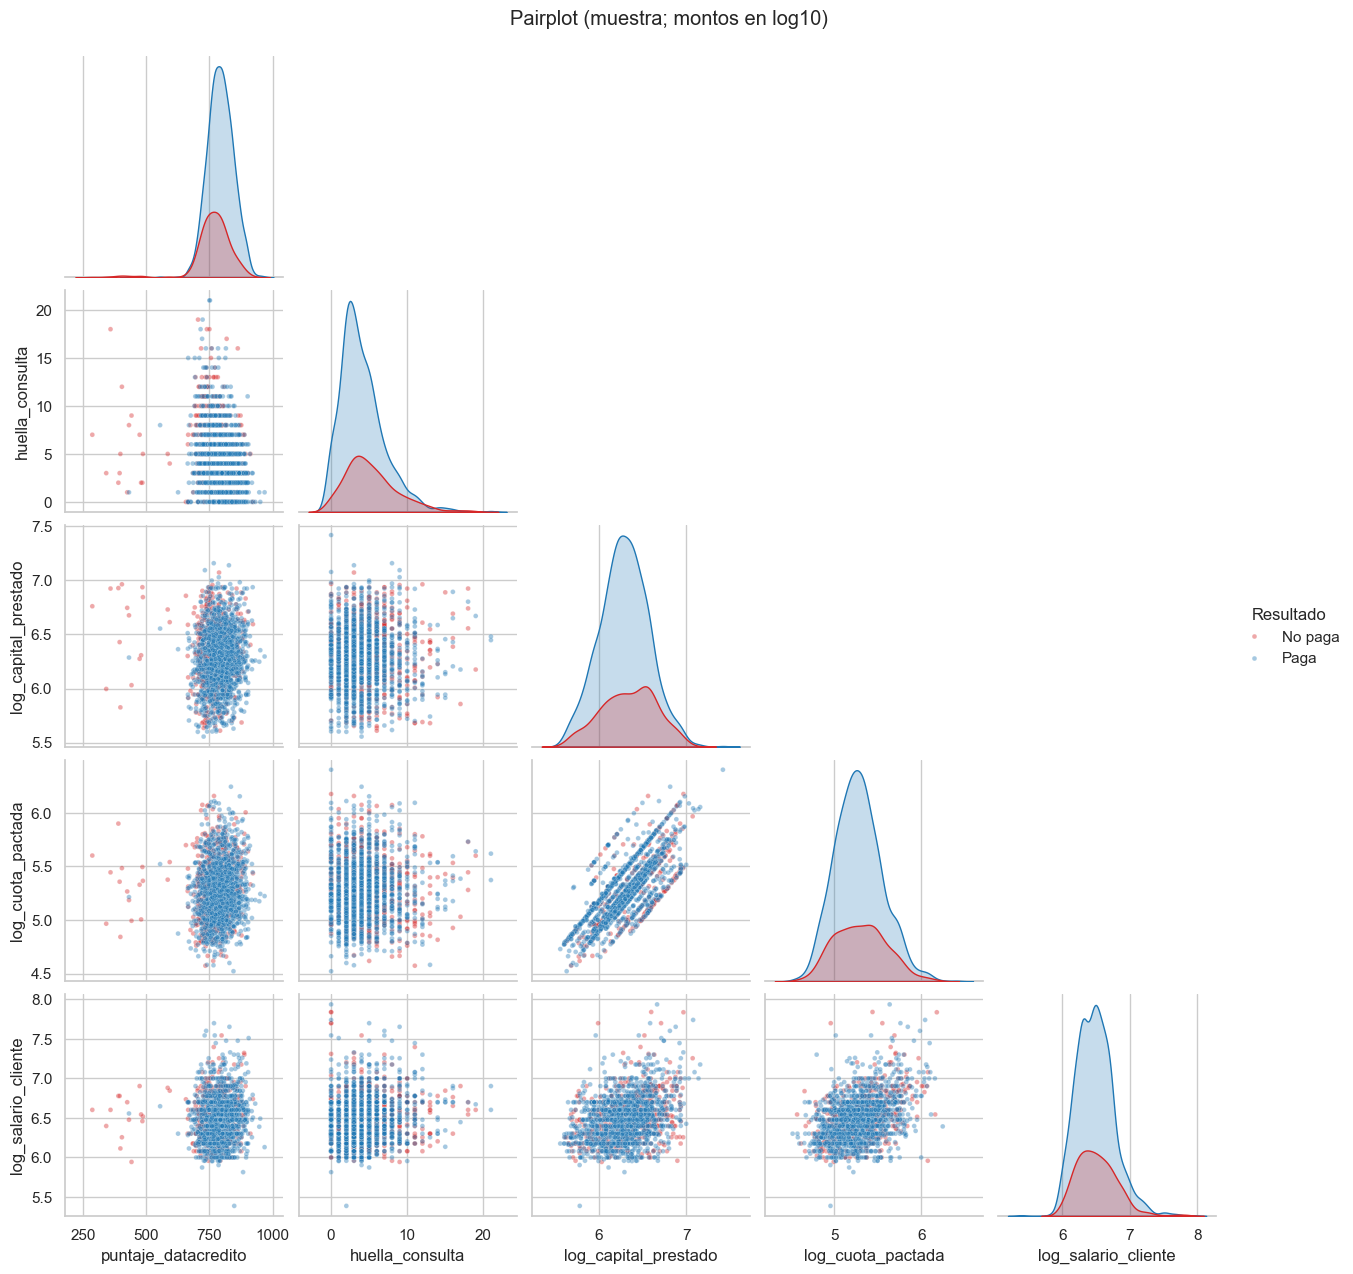

In [42]:
vars_pair = ["capital_prestado", "cuota_pactada", "salario_cliente", "puntaje_datacredito", "huella_consulta"]
muestra = pd.concat([df[df[TARGET] == 0], df[df[TARGET] == 1].sample(1500, random_state=42)])
muestra_pair = muestra[vars_pair + [TARGET]].copy()
for c in ["capital_prestado", "cuota_pactada", "salario_cliente"]:
    muestra_pair[f"log_{c}"] = np.log10(muestra_pair.pop(c))
muestra_pair["Resultado"] = muestra_pair.pop(TARGET).map({0: "No paga", 1: "Paga"})

g = sns.pairplot(muestra_pair, hue="Resultado", palette={"Paga": "tab:blue", "No paga": "tab:red"},
                 plot_kws={"alpha": 0.4, "s": 12}, diag_kind="kde", corner=True)
g.figure.suptitle("Pairplot (muestra; montos en log10)", y=1.02)
plt.show()

**Lectura.** `log_capital_prestado` y `log_cuota_pactada` forman una banda casi lineal (la cuota depende del capital y del plazo). Los incumplimientos (rojo) **no forman un cúmulo propio**: están mezclados con los pagadores en casi todos los planos, lo que confirma que ninguna pareja de variables separa por sí sola a los dos grupos. Solo en `huella_consulta` y `puntaje_datacredito` hay un ligero desplazamiento hacia valores peores.

### 7.3 Dispersión con variables categóricas (`hue`)

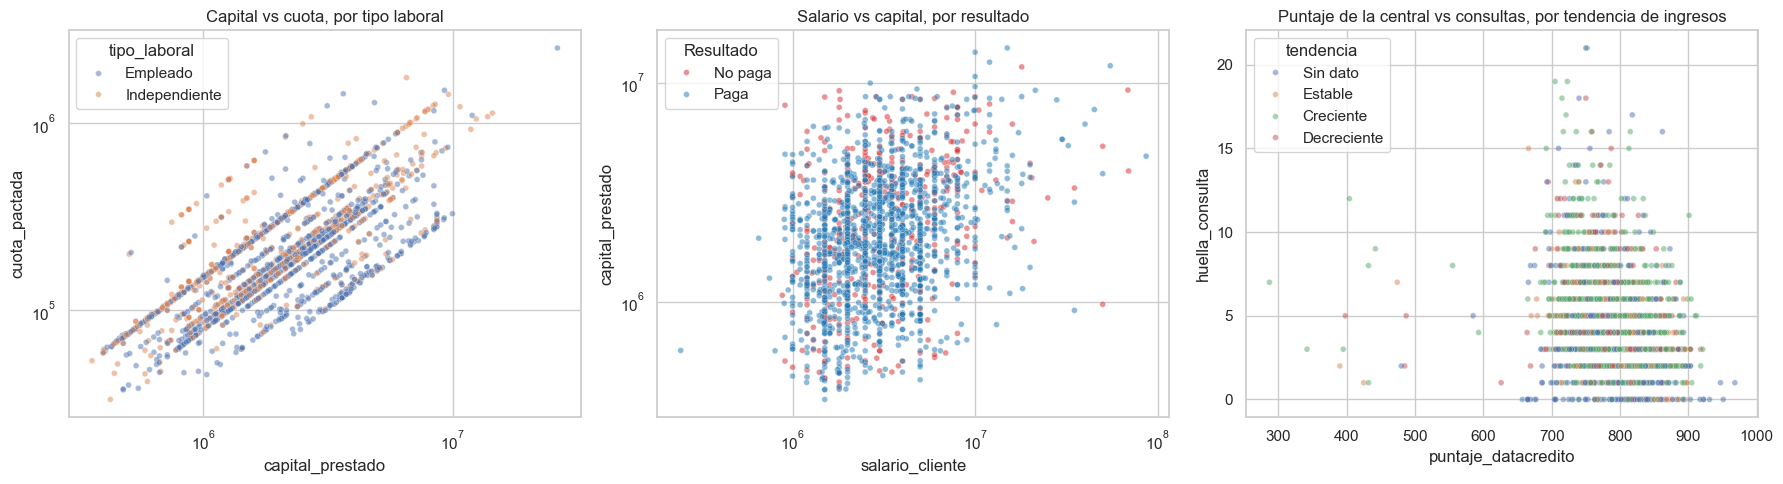

In [43]:
m = muestra.assign(Resultado=muestra[TARGET].map({0: "No paga", 1: "Paga"}))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=m, x="capital_prestado", y="cuota_pactada", hue="tipo_laboral", alpha=0.5, s=18, ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Capital vs cuota, por tipo laboral")

sns.scatterplot(data=m.dropna(subset=["salario_cliente"]), x="salario_cliente", y="capital_prestado",
                hue="Resultado", palette={"Paga": "tab:blue", "No paga": "tab:red"}, alpha=0.5, s=18, ax=axes[1])
axes[1].set(xscale="log", yscale="log", title="Salario vs capital, por resultado")

m_t = m.assign(tendencia=m["tendencia_ingresos"].astype(object).fillna("Sin dato"))
sns.scatterplot(data=m_t, x="puntaje_datacredito", y="huella_consulta", hue="tendencia", alpha=0.5, s=18, ax=axes[2])
axes[2].set(title="Puntaje de la central vs consultas, por tendencia de ingresos")
plt.tight_layout()
plt.show()

**Lectura.** (1) La relación capital–cuota es la misma para empleados e independientes: la política de cuotas no depende del tipo laboral. (2) No hay un umbral de salario o de capital que aísle a los incumplidos. (3) Los clientes sin dato de tendencia se distribuyen por todo el plano puntaje–consultas, lo que indica que su perfil crediticio no difiere sistemáticamente del resto.

### 7.4 Tablas cruzadas multivariables

Tasa de pago a tiempo (%) por tipo laboral x tendencia de ingresos


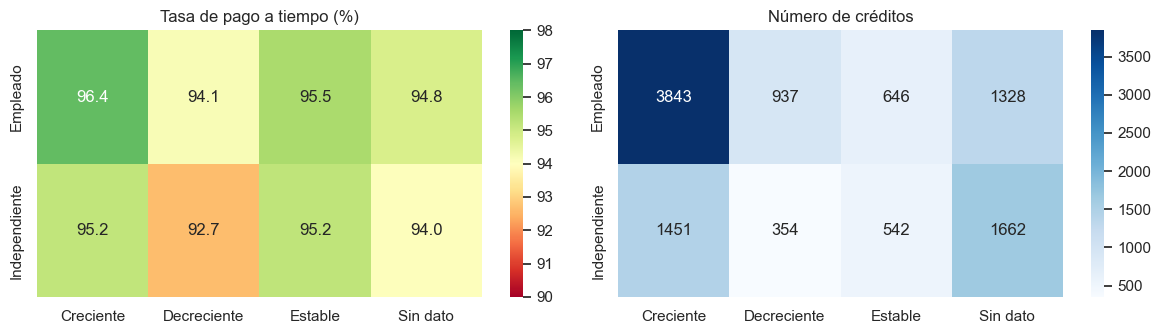

In [44]:
print("Tasa de pago a tiempo (%) por tipo laboral x tendencia de ingresos")
tasa_cruce = pd.pivot_table(df_cat, values=TARGET, index="tipo_laboral", columns="tendencia_ingresos", aggfunc="mean") * 100
casos_cruce = pd.pivot_table(df_cat, values=TARGET, index="tipo_laboral", columns="tendencia_ingresos", aggfunc="count")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.heatmap(tasa_cruce, annot=True, fmt=".1f", cmap="RdYlGn", vmin=90, vmax=98, ax=axes[0])
axes[0].set(title="Tasa de pago a tiempo (%)", xlabel="", ylabel="")
sns.heatmap(casos_cruce, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set(title="Número de créditos", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

In [45]:
# Tasa de pago por tipo de crédito x tipo laboral (solo códigos con volumen)
frecuentes = df_cat["tipo_credito"].value_counts().loc[lambda s: s > 100].index
pd.pivot_table(df_cat[df_cat["tipo_credito"].isin(frecuentes)], values=TARGET,
               index="tipo_credito", columns="tipo_laboral", aggfunc=["mean", "count"]).round(3)

mean                  count              
tipo_laboral Empleado Independiente Empleado Independiente
tipo_credito                                              
10               0.97          0.98       75            41
4                0.96          0.94     5052          2695
9                0.96          0.95     1604          1272

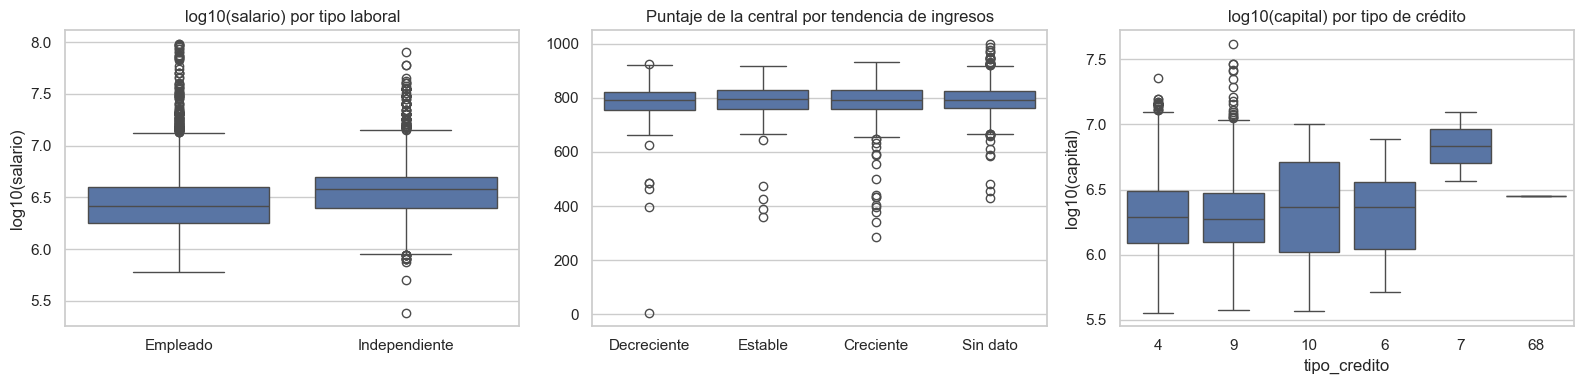

In [46]:
# Variables numéricas por segmento categórico (log10 del salario por tipo laboral)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x="tipo_laboral", y=np.log10(df["salario_cliente"]), ax=axes[0])
axes[0].set(title="log10(salario) por tipo laboral", ylabel="log10(salario)", xlabel="")
sns.boxplot(data=df_cat.assign(puntaje_dc=df["puntaje_datacredito"]), x="tendencia_ingresos", y="puntaje_dc",
            order=["Decreciente", "Estable", "Creciente", "Sin dato"], ax=axes[1])
axes[1].set(title="Puntaje de la central por tendencia de ingresos", xlabel="", ylabel="")
sns.boxplot(data=df, x=df_cat["tipo_credito"], y=np.log10(df["capital_prestado"]),
            order=df_cat["tipo_credito"].value_counts().index, ax=axes[2])
axes[2].set(title="log10(capital) por tipo de crédito", ylabel="log10(capital)", xlabel="tipo_credito")
plt.tight_layout()
plt.show()

**Interpretación.** En ambos tipos laborales "Decreciente" es la peor tendencia conocida (empleados 94.1 %, independientes 92.7 %) y "Creciente" la mejor (96.4 % y 95.2 %); en independientes "Estable" iguala a "Creciente". Los **independientes con ingresos decrecientes (92.7 %, 354 créditos)** son el subgrupo identificable de menor tasa de pago. Los "Sin dato" quedan en un punto intermedio (94.8 % y 94.0 %) y son el grupo más numeroso entre independientes (1 662). Los tipos de crédito 4 y 9 se comportan casi igual por segmento laboral, así que `tipo_credito` aporta poco una vez controlados los demás factores. Los boxplots por segmento sirven además para detectar si conviene imputar con la mediana **del segmento** (p. ej. salario por tipo laboral) en vez de la global.

## 8. Atributos derivados (calculados) que pueden ser útiles

En riesgo de crédito las **razones** (capacidad de pago, endeudamiento) suelen predecir mejor que los montos absolutos. Se proponen, se calculan y se mide su relación con el objetivo para decidir cuáles merecen pasar a la etapa de modelado.

| Atributo | Fórmula | Razón de negocio |
|---|---|---|
| `carga_cuota_salario` | cuota_pactada / salario_cliente | Peso de la cuota sobre el ingreso declarado |
| `carga_cuota_ingreso_dc` | cuota_pactada / promedio_ingresos_datacredito | Peso de la cuota sobre el ingreso verificado |
| `capital_sobre_salario` | capital_prestado / salario_cliente | Tamaño del crédito relativo al ingreso |
| `deuda_otros_sobre_salario` | total_otros_prestamos / salario_cliente | Nivel de endeudamiento previo |
| `ratio_ingreso_declarado_vs_dc` | salario_cliente / promedio_ingresos_datacredito | Consistencia entre ingreso declarado y reportado |
| `pago_total_sobre_capital` | cuota × plazo / capital | Proxy del costo total del crédito |
| `total_creditos_sectores` | suma de los tres `creditos_sector*` | Diversificación del historial |
| `pct_sector_financiero` | creditos_sectorFinanciero / total sectores | Dependencia del sector financiero |
| `tiene_mora` | saldo_mora > 0 | Indicador binario de mora vigente |
| `mora_sobre_saldo` | saldo_mora / saldo_total | Gravedad de la mora |
| `sin_ingresos_datacredito` | promedio_ingresos_datacredito es nulo | Marca el grupo "sin historial" |
| `consultas_altas` | huella_consulta ≥ 6 | Búsqueda intensa de crédito |
| `mes`, `dia_semana`, `hora`, `es_fin_de_semana` | de `fecha_prestamo` | Efectos temporales |
| `grupo_edad` | edad en tramos | Segmentos de ciclo de vida |

In [47]:
def crear_atributos(datos: pd.DataFrame) -> pd.DataFrame:
    d = datos.copy()
    sectores = d[["creditos_sectorFinanciero", "creditos_sectorCooperativo", "creditos_sectorReal"]].sum(axis=1)

    d["carga_cuota_salario"] = d["cuota_pactada"] / d["salario_cliente"]
    d["carga_cuota_ingreso_dc"] = d["cuota_pactada"] / d["promedio_ingresos_datacredito"]
    d["capital_sobre_salario"] = d["capital_prestado"] / d["salario_cliente"]
    d["deuda_otros_sobre_salario"] = d["total_otros_prestamos"] / d["salario_cliente"]
    d["ratio_ingreso_declarado_vs_dc"] = d["salario_cliente"] / d["promedio_ingresos_datacredito"]
    d["pago_total_sobre_capital"] = d["cuota_pactada"] * d["plazo_meses"] / d["capital_prestado"]
    d["total_creditos_sectores"] = sectores
    d["pct_sector_financiero"] = d["creditos_sectorFinanciero"] / sectores.replace(0, np.nan)
    d["tiene_mora"] = (d["saldo_mora"] > 0).astype("boolean").where(d["saldo_mora"].notna())
    d["mora_sobre_saldo"] = d["saldo_mora"] / d["saldo_total"].replace(0, np.nan)
    d["sin_ingresos_datacredito"] = d["promedio_ingresos_datacredito"].isna()
    d["consultas_altas"] = d["huella_consulta"] >= 6
    d["mes"] = d["fecha_prestamo"].dt.month
    d["dia_semana"] = d["fecha_prestamo"].dt.dayofweek
    d["hora"] = d["fecha_prestamo"].dt.hour
    d["es_fin_de_semana"] = d["dia_semana"] >= 5
    d["grupo_edad"] = pd.cut(d["edad_cliente"], [17, 30, 40, 50, 60, 100],
                             labels=["18-30", "31-40", "41-50", "51-60", "61+"])
    return d


df_fe = crear_atributos(df)
DERIVADAS_NUM = ["carga_cuota_salario", "carga_cuota_ingreso_dc", "capital_sobre_salario", "deuda_otros_sobre_salario",
                 "ratio_ingreso_declarado_vs_dc", "pago_total_sobre_capital", "total_creditos_sectores",
                 "pct_sector_financiero", "mora_sobre_saldo"]
DERIVADAS_BIN = ["tiene_mora", "sin_ingresos_datacredito", "consultas_altas", "es_fin_de_semana"]

todas_der = DERIVADAS_NUM + DERIVADAS_BIN
eval_fe = pd.DataFrame(index=todas_der)
eval_fe["% nulos"] = 100 * df_fe[todas_der].isna().mean()
eval_fe["mediana"] = df_fe[DERIVADAS_NUM].median()
eval_fe["skewness"] = df_fe[DERIVADAS_NUM].skew()
eval_fe["spearman_vs_objetivo"] = [df_fe[c].astype(float).corr(df_fe[TARGET], method="spearman") for c in todas_der]
eval_fe.sort_values("spearman_vs_objetivo", key=abs, ascending=False)

,% nulos,mediana,skewness,spearman_vs_objetivo
mora_sobre_saldo,8.78,0.00,52.56,-0.11
tiene_mora,1.45,NaN,NaN,-0.11
consultas_altas,0.00,NaN,NaN,-0.06
ratio_ingreso_declarado_vs_dc,27.55,1.81,19.63,-0.05
es_fin_de_semana,0.00,NaN,NaN,-0.05
carga_cuota_ingreso_dc,27.29,0.13,39.19,-0.04
deuda_otros_sobre_salario,0.98,0.33,97.76,0.03
capital_sobre_salario,0.98,0.64,2.83,-0.03
sin_ingresos_datacredito,0.00,NaN,NaN,-0.03
pct_sector_financiero,6.54,0.67,-0.56,0.02


In [48]:
# Comparación: ¿la razón tiene más señal que sus componentes por separado?
comparacion = pd.DataFrame({
    "variable": ["cuota_pactada", "salario_cliente", "carga_cuota_salario",
                 "capital_prestado", "capital_sobre_salario", "huella_consulta", "consultas_altas"],
})
comparacion["spearman_vs_objetivo"] = [df_fe[c].astype(float).corr(df_fe[TARGET], method="spearman") for c in comparacion["variable"]]
comparacion

,variable,spearman_vs_objetivo
0,cuota_pactada,-0.01
1,salario_cliente,-0.00
2,carga_cuota_salario,-0.01
3,capital_prestado,-0.04
4,capital_sobre_salario,-0.03
5,huella_consulta,-0.07
6,consultas_altas,-0.06


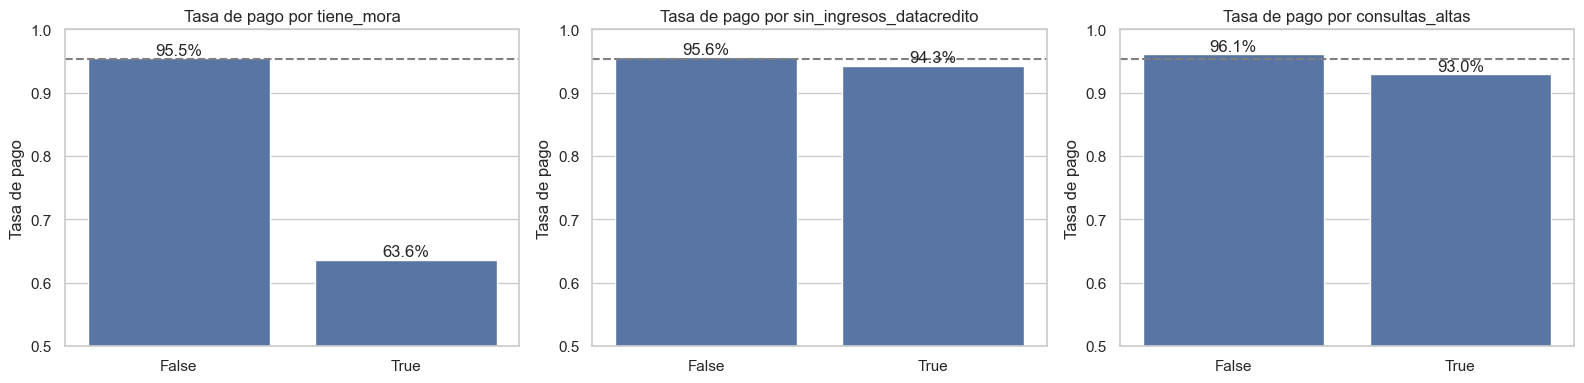

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tiene_mora", "sin_ingresos_datacredito", "consultas_altas"]):
    t = df_fe.groupby(df_fe[col].astype(object), observed=True)[TARGET].mean()
    sns.barplot(x=t.index.astype(str), y=t.values, ax=ax)
    ax.axhline(tasa_global, ls="--", color="gray")
    ax.set(title=f"Tasa de pago por {col}", ylim=(0.5, 1), xlabel="", ylabel="Tasa de pago")
    for i, v in enumerate(t.values):
        ax.text(i, v + 0.005, f"{v:.1%}", ha="center")
plt.tight_layout()
plt.show()

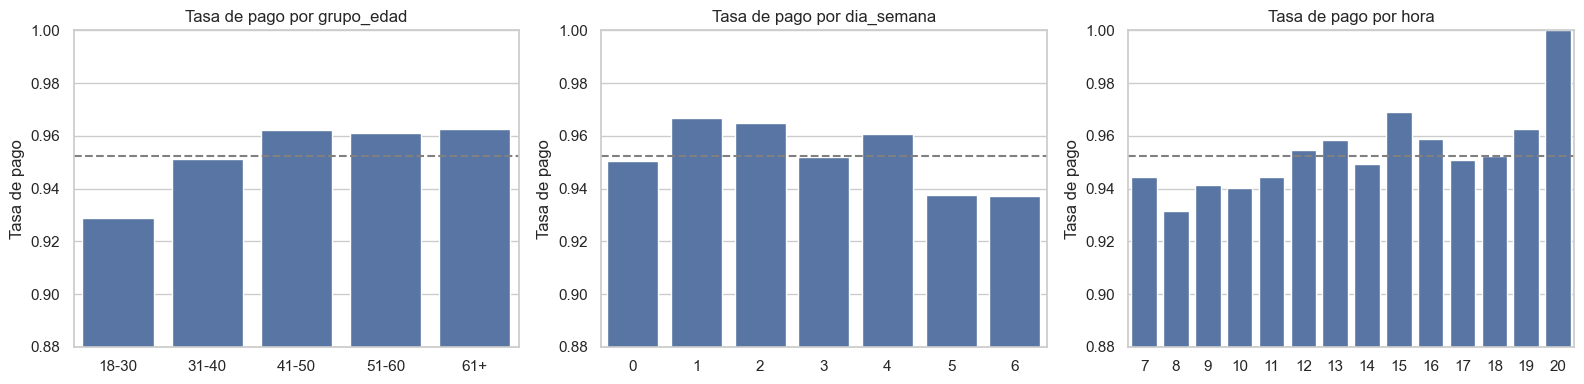

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, orden in [(axes[0], "grupo_edad", None), (axes[1], "dia_semana", None), (axes[2], "hora", None)]:
    t = df_fe.groupby(col, observed=True)[TARGET].agg(["mean", "count"])
    sns.barplot(x=t.index.astype(str), y=t["mean"].values, ax=ax)
    ax.axhline(tasa_global, ls="--", color="gray")
    ax.set(title=f"Tasa de pago por {col}", ylim=(0.88, 1), xlabel="", ylabel="Tasa de pago")
plt.tight_layout()
plt.show()

**Interpretación.**

- **Indicadores binarios útiles:** `tiene_mora` (ρ = −0.11) y `mora_sobre_saldo` (−0.11) son los atributos derivados con más asociación: los 55 créditos con mora vigente pagan solo ≈ 64 % frente a ≈ 95 %. `consultas_altas` (≥ 6 consultas, 2 859 créditos) baja la tasa a ≈ 93.0 % frente a 96.1 % (ρ = −0.06). `es_fin_de_semana` (ρ = −0.05) recoge el efecto de los desembolsos de sábado y domingo (≈ 93.7 %). `sin_ingresos_datacredito` captura el grupo sin historial (≈ −1.3 pp, ρ = −0.03).
- **Razones:** `ratio_ingreso_declarado_vs_dc` (ρ = −0.05: cuando el salario declarado supera mucho al ingreso reportado por la central, el riesgo sube), `carga_cuota_ingreso_dc` (−0.04), `capital_sobre_salario` (−0.03) y `deuda_otros_sobre_salario` (+0.03) tienen asociación monótona baja, y `carga_cuota_salario` (−0.01) **no mejora** a sus componentes (`capital_prestado` −0.04). Con 27 % de nulos en las que dependen del ingreso de la central, su aporte debe confirmarse con un modelo no lineal; se conservan como candidatas, no como garantía.
- **`pago_total_sobre_capital`** (cuota × plazo / capital) tiene mediana ≈ 0.89, es decir **menor que 1**: el total de cuotas es inferior al capital prestado. Eso sugiere que `cuota_pactada` no incluye el capital completo (o que `capital_prestado` incluye conceptos adicionales). **Hay que validar esta definición con el negocio**; su asociación con el objetivo es nula (ρ ≈ 0).
- **Variables temporales y edad:** `hora` no muestra un patrón claro; `dia_semana` solo destaca por el fin de semana; `grupo_edad` conserva el patrón visto (≤ 30 años pagan algo peor: ≈ 92.9 %).
- Todas las razones deben calcularse con **control de división por cero** y después de la imputación/limpieza (el salario nulo genera razones nulas).

## 9. Transformaciones que se pueden aplicar
### 9.1 Efecto de `log1p` sobre la asimetría

In [51]:
candidatas = desc.index[(desc["skewness"].astype(float) > 1) & (desc["mín"].astype(float) >= 0)]
trans = pd.DataFrame({
    "skew_original": df[candidatas].skew(),
    "skew_log1p": np.log1p(df[candidatas]).skew(),
})
trans["mejora"] = trans["skew_original"].abs() - trans["skew_log1p"].abs()
trans.sort_values("mejora", ascending=False)

,skew_original,skew_log1p,mejora
total_otros_prestamos,38.46,-3.61,34.86
saldo_mora,40.57,15.47,25.09
saldo_total,20.20,-1.61,18.59
salario_cliente,8.68,0.79,7.89
capital_prestado,3.72,0.11,3.61
cuota_pactada,3.79,0.40,3.39
promedio_ingresos_datacredito,4.28,-1.09,3.20
creditos_sectorFinanciero,2.70,-0.08,2.62
creditos_sectorReal,3.16,0.63,2.53
creditos_sectorCooperativo,4.22,2.30,1.92


**Lectura.** `log1p` reduce mucho la asimetría de los montos: `capital_prestado` (3.7 → 0.1), `cuota_pactada` (3.8 → 0.4), `salario_cliente` (8.7 → 0.8), `saldo_total` (20 → −1.6), `promedio_ingresos_datacredito` (4.3 → −1.1); en `total_otros_prestamos` pasa de 38 a −3.6 (la cola izquierda viene de los ceros). **No basta** en variables dominadas por ceros (`saldo_mora`: 40 → 15; `creditos_sectorCooperativo`: 4.2 → 2.3): ahí conviene un **indicador (¿> 0?)**, además o en vez del valor.

### 9.2 Resumen de transformaciones recomendadas

| Tema | Variables | Transformación propuesta | Motivo |
|---|---|---|---|
| Asimetría | capital, cuota, salario, otros préstamos, saldo_total, ingresos central, razones | `log1p` | Distribuciones log-normales |
| Extremos | total_otros_prestamos, saldo_mora, salario | Recorte (*winsorize*) en percentiles 1–99 | Pocos valores dominan media y varianza |
| Nulos | promedio_ingresos_datacredito, tendencia_ingresos, saldos, edad, salario, puntaje_datacredito | Imputar (mediana, idealmente por segmento) **+ indicador de nulo** | Nulos informativos (27 % sin historial) |
| Categórica nominal | tipo_credito, tipo_laboral | Agrupar códigos raros (< 1 %) en "Otros" + *one-hot* (o *target encoding* con validación cruzada) | Categorías poco pobladas inestables |
| Categórica ordinal | tendencia_ingresos | Codificación ordinal (Decreciente = 0, Estable = 1, Creciente = 2) y nivel "Sin dato" | Respeta el orden |
| Discretización | plazo_meses, huella_consulta, edad | Opcional: agrupar en tramos | Relación monótona/escalonada con el riesgo |
| Escalado | todas las numéricas (modelos lineales/distancia) | `RobustScaler` o estandarización tras log | Robusto a outliers; no necesario para árboles |
| Desbalance | objetivo | Pesos de clase / submuestreo / SMOTE solo dentro de cada fold | Clase 0 = 4.8 % |
| Fecha | fecha_prestamo | Partición temporal; atributos mes/día/hora | Evitar fuga y validar a futuro |
| Alerta | puntaje | Confirmar disponibilidad en originación; excluir si es posterior | Posible fuga de información |

## 10. Reglas de validación de datos

Con lo observado se define un **esquema de validación** que se usará en la etapa de calidad de datos del pipeline. Distingue dos niveles:

- **Regla dura:** la violación es un error (el dato se anula o el registro se rechaza).
- **Alerta:** el valor es posible pero inusual (percentiles 0.5 y 99.5 de los datos); se registra, no se rechaza. Sirve además para detectar *drift* en producción.

In [52]:
NO_NULOS = ["tipo_credito", "fecha_prestamo", "capital_prestado", "tipo_laboral", "cuota_pactada",
            "puntaje", "cant_creditosvigentes", "huella_consulta", "creditos_sectorFinanciero",
            "creditos_sectorCooperativo", "creditos_sectorReal", TARGET]

CATALOGOS = {
    "tipo_credito": sorted(df_original["tipo_credito"].astype(int).unique().tolist()),
    "tipo_laboral": CAT_LABORAL,
    "tendencia_ingresos": CAT_TENDENCIA,
    TARGET: [0, 1],
}

esquema = []
for col in df_original.columns:
    fila = {"columna": col, "tipo_esperado": CARACTERIZACION[col][0], "acepta_nulos": col not in NO_NULOS}
    if col in RANGO_DURO:
        lo, hi = RANGO_DURO[col]
        fila["rango_duro"] = (lo, hi)
        s = df[col] if col in df.columns else df_limpio[col]
        fila["alerta_p0.5-p99.5"] = tuple(np.round(s.quantile([0.005, 0.995]).tolist(), 1))
    if col in CATALOGOS:
        fila["catalogo"] = CATALOGOS[col]
    esquema.append(fila)

esquema = pd.DataFrame(esquema).set_index("columna")
pd.set_option("display.max_colwidth", 60)
esquema

,tipo_esperado,acepta_nulos,catalogo,rango_duro,alerta_p0.5-p99.5
columna,,,,,
tipo_credito,Categórica,False,"[4, 6, 7, 9, 10, 68]",NaN,NaN
fecha_prestamo,Fecha,False,NaN,NaN,NaN
capital_prestado,Numérica,False,NaN,"(1, None)","(420000.0, 11080043.4)"
plazo_meses,Numérica,True,NaN,"(1, 60)","(2.0, 36.0)"
edad_cliente,Numérica,True,NaN,"(18, 100)","(21.0, 69.0)"
tipo_laboral,Categórica,False,"[Empleado, Independiente]",NaN,NaN
salario_cliente,Numérica,True,NaN,"(100000, 100000000)","(908526.0, 35000000.0)"
total_otros_prestamos,Numérica,True,NaN,"(0, None)","(0.0, 76462730.0)"
cuota_pactada,Numérica,False,NaN,"(1, None)","(46545.8, 1288909.1)"


In [53]:
# Reglas entre columnas (coherencia). Se evalúan sobre los datos originales.
REGLAS_CRUZADAS = {
    "saldo_principal <= saldo_total":      lambda d: d["saldo_principal"] > d["saldo_total"],
    "saldo_mora <= saldo_total":           lambda d: d["saldo_mora"] > d["saldo_total"],
    "cuota_pactada < capital_prestado":    lambda d: d["cuota_pactada"] >= d["capital_prestado"],
    "puntaje <= 100":                      lambda d: d["puntaje"] > 100,
    "fecha_prestamo no es futura":         lambda d: d["fecha_prestamo"] > pd.Timestamp.today(),
}


def validar(datos: pd.DataFrame) -> pd.DataFrame:
    """Devuelve cuántas filas violan cada regla. Un esquema sano devuelve 0 en reglas duras."""
    filas = []
    for col in datos.columns:
        if col in NO_NULOS and datos[col].isna().any():
            filas.append({"regla": f"{col}: no admite nulos", "violaciones": int(datos[col].isna().sum())})
        if col in RANGO_DURO:
            lo, hi = RANGO_DURO[col]
            n = int(fuera_de_rango(datos[col].astype(float), lo, hi).sum())
            filas.append({"regla": f"{col}: dentro de [{lo}, {hi}]", "violaciones": n})
        if col in CATALOGOS:
            v = datos[col].astype(object)
            filas.append({"regla": f"{col}: pertenece al catálogo", "violaciones": int((v.notna() & ~v.isin(CATALOGOS[col])).sum())})
    for nombre, f in REGLAS_CRUZADAS.items():
        try:
            filas.append({"regla": nombre, "violaciones": int(f(datos).sum())})
        except KeyError:
            continue                      # la columna ya fue eliminada
    out = pd.DataFrame(filas).set_index("regla")
    out["% filas"] = (100 * out["violaciones"] / len(datos)).round(2)
    return out


val_antes = validar(df_original)
val_despues = validar(df)
reporte_val = val_antes.join(val_despues, lsuffix="_antes", rsuffix="_después", how="outer").fillna(0)
reporte_val[(reporte_val["violaciones_antes"] > 0) | (reporte_val["violaciones_después"] > 0)]

,violaciones_antes,% filas_antes,violaciones_después,% filas_después
regla,,,,
"edad_cliente: dentro de [18, 100]",150,1.39,0.00,0.00
"plazo_meses: dentro de [1, 60]",1,0.01,0.00,0.00
"promedio_ingresos_datacredito: dentro de [1, None]",7,0.07,0.00,0.00
"puntaje_datacredito: dentro de [1, 999]",146,1.36,0.00,0.00
"salario_cliente: dentro de [100000, 100000000]",105,0.98,0.00,0.00
tendencia_ingresos: pertenece al catálogo,58,0.54,0.00,0.00


**Resumen de reglas de validación propuestas** (para implementar con `pydantic` / reglas en el pipeline):

1. **Esquema de entrada:** 23 columnas con los tipos de la sección 4; ninguna adicional ni faltante. Para modelado se descartan `saldo_principal` y `saldo_mora_codeudor` (21 columnas).
2. **Nulos:** no se permiten en `tipo_credito`, `fecha_prestamo`, `capital_prestado`, `tipo_laboral`, `cuota_pactada`, `puntaje`, conteos y objetivo. Sí se admiten (y se señalizan) en saldos, `plazo_meses`, `edad_cliente`, `salario_cliente`, `puntaje_datacredito`, `promedio_ingresos_datacredito` y `tendencia_ingresos`.
3. **Catálogos:** `tipo_laboral ∈ {Empleado, Independiente}`; `tendencia_ingresos ∈ {Decreciente, Estable, Creciente}`; `Pago_atiempo ∈ {0, 1}`; `tipo_credito` dentro de los códigos conocidos (un código nuevo genera alerta).
4. **Rangos duros:** edad 18–100; plazo 1–60 meses; salario 100 000–100 M; `puntaje_datacredito` 1–999; montos, saldos y conteos ≥ 0; capital y cuota > 0.
5. **Coherencia entre columnas:** `saldo_mora ≤ saldo_total`; `cuota_pactada < capital_prestado`; `fecha_prestamo` no futura; los conteos por sector **no** tienen por qué sumar `cant_creditosvigentes` (hay diferencias de −2 a +12), por lo que no se impone esa regla.
6. **Alertas por percentiles:** valores fuera de p0.5–p99.5 se registran y alimentan el monitoreo de *drift*.
7. **Marcadores centinela:** cualquier edad 122, puntaje de central ≤ 0 o texto como "N/A" se trata como nulo.

## 11. Conclusiones y siguientes pasos

**Calidad de datos**

- 10 763 créditos, sin duplicados. Los nulos "oficiales" se concentran en ingresos de la central (27 %), pero había además **datos inválidos escondidos**: números dentro de `tendencia_ingresos` (58), edad centinela 122 (144), salarios de hasta 22 mil millones, puntajes de la central ≤ 0 (146). Todos se llevaron a `NaN` mediante una función (`limpiar`) reutilizable.
- Se eliminaron `saldo_mora_codeudor` (constante en la práctica) y `saldo_principal` (redundante con `saldo_total`).

**Objetivo y desbalance**

- Solo 4.8 % de los créditos no se paga a tiempo (~20:1). Usar AUC-PR/recall/F1/KS, validación estratificada y manejo del desbalance.

**Señales predictivas**

- **`puntaje` separa casi perfectamente** los dos grupos (≤ 50 → siempre incumple; > 90 → siempre paga). Es una **posible fuga de información** que debe resolverse con el negocio antes de modelar.
- Aparte de `puntaje`, las señales son débiles pero coherentes: mora vigente (`saldo_mora` > 0, ≈ 64 % de pago), más consultas recientes, menor puntaje de la central, ingresos decrecientes o sin historial, clientes jóvenes, capital alto e independientes → menor probabilidad de pago.
- Las variables de monto son log-normales; las razones (cuota/ingreso, capital/ingreso) son candidatas naturales para capturar capacidad de pago.

**Riesgos y puntos a validar**

- **Etiqueta inmadura:** la tasa de pago sube en los créditos recientes y el volumen cae; usar partición temporal y revisar el horizonte de observación.
- `pago_total_sobre_capital` < 1 sugiere una definición pendiente de `cuota_pactada` o `capital_prestado`.
- Los rangos de la sección 2 son hipótesis razonables, a confirmar con riesgo/negocio.
- `tipo_credito` tiene categorías con muy pocos casos (6, 7, 68).

**Siguientes pasos**

1. Confirmar con negocio la disponibilidad de `puntaje` al momento de originación.
2. Implementar la función `limpiar`, el esquema y `validar` en el pipeline de datos.
3. Construir el pipeline de preparación: imputación + indicadores de nulo, `log1p`, agrupación de categorías raras, codificación y atributos derivados.
4. Modelar con partición temporal, comparando con y sin `puntaje`, y evaluar con métricas aptas para desbalance.